# Gamma Spectrometry App walkthrough: every function, in the order it is called

This notebook runs the pipeline step by step on the real 2021 NaI(Tl) data and shows, for
each function, **what goes in, what comes out, and how it works** (including the maths).

The order follows the data:

| Part | Step | What happens |
|---|---|---|
| 0 | The app in pictures | one capture through every step, before and after each one: start here |
| A | 1. Ingestion | ASCII capture files → lossless integer codes → HDF5 store |
| B | 2. Characterisation | pulse template, analytic pulse model, noise |
| C | 3. Pre-processing | interference removal → pole-zero correction → baseline tracker |
| D | 4. Detection and events | optimal filter → successive cancellation → event list |
| E | 5–6. Pile-up resolution | TM, HYPER and least-squares fits on a real cluster; the pile-up solver in the pipeline |
| G | 7. Calibration and background subtraction | keV axis for each run, gain matching, net spectrum |
| H | Benchmark | the same pulses through a naive `find_peaks` count, an emulated analog chain and this app |
| I | 9. Configuration | one run file selects input, stages and parameters; the runner executes it |
| J | 10. Simulation and streaming | a synthetic signal with known truth; continuous input in overlapping frames; live spectrum |
| K | 11. The app | the browser UI: a front end for the run file |
| F | Evaluation tools | how the numbers in the docs were measured |

Conventions: time is in **samples** (1 sample = 1/1.8 MHz = 0.556 µs) unless stated;
voltages are in volts; the raw pulses are negative and are flipped to positive early on.

*Rebuild with `python docs/build_walkthrough.py` (needs the local `data/` folder).*

In [1]:
import numpy as np, matplotlib.pyplot as plt, json, tempfile
from pathlib import Path
import gamma_spectrometry
from gamma_spectrometry import rawio, store, signal, template, noise, interference, baseline, preprocess, detect, events, pipeline, spectrum
from gamma_spectrometry import plotting as P
%matplotlib inline
np.set_printoptions(precision=5, suppress=False, linewidth=110, threshold=24, edgeitems=4)
ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
RAW = ROOT / "ADC_raw_output"
SRC_STORE = ROOT / "data/source_first100.h5"
BKG_STORE = ROOT / "data/background.h5"
TEMPLATE = ROOT / "data/characterization/background/template.h5"
TMP = Path(tempfile.mkdtemp())
FS = 1.8e6
print("Gamma Spectrometry App", gamma_spectrometry.__version__)

Gamma Spectrometry App 0.3.0


---
# Part 0: The app in pictures

Before going function by function (Parts A–J), this part follows **one recorded capture**
through the whole program and shows, for every step, the signal **before and after**. Each
figure answers three questions:
* what goes in;
* what comes out;
* why it matters for the spectrum.

## 0.1 What this software replaces

A gamma-ray spectrometer turns each gamma ray absorbed in the crystal into one number, its
energy, and counts how often each energy occurs. The **classic** NaI(Tl) setup does this
with **analog electronics**:
* a **shaping amplifier** filters each preamplifier pulse into a smooth, slower bump;
* a **multichannel analyser (MCA)** holds the peak of each bump, digitises that one value,
  and adds one count to the matching channel.

The **Gamma Spectrometry App** keeps the detector, the photomultiplier (PMT) and the preamplifier, then
digitises the preamplifier output directly with a fast ADC. Everything the shaping
amplifier and MCA did, and more, happens in software on a PC.

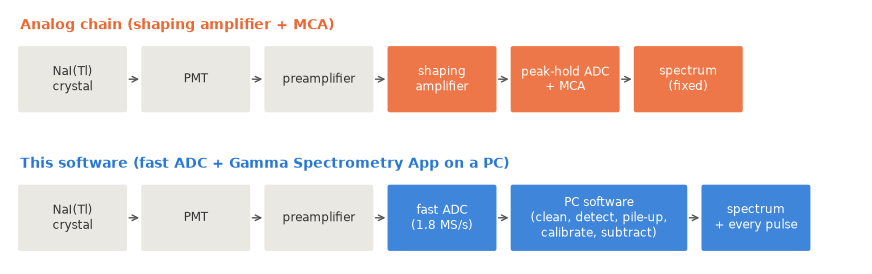

In [2]:
from gamma_spectrometry import simulate, sources, stream
import matplotlib.patches as mpatches
fig, ax = plt.subplots(figsize=(11, 3.3))
ax.set_xlim(0, 12.6); ax.set_ylim(0, 3.3); ax.axis("off")
def chain(y, boxes, colors):
    x = 0.15
    for i, (label, col) in enumerate(zip(boxes, colors)):
        w = 2.55 if "PC software" in label else 1.55
        ax.add_patch(mpatches.FancyBboxPatch((x, y), w, 0.8, boxstyle="round,pad=0.03", fc=col, ec="none", alpha=0.9))
        ax.text(x + w / 2, y + 0.4, label, ha="center", va="center", fontsize=8.5, color="white" if col != "#e8e6df" else "#333")
        if i < len(boxes) - 1:
            ax.annotate("", xy=(x + w + 0.25, y + 0.4), xytext=(x + w + 0.02, y + 0.4), arrowprops=dict(arrowstyle="->", color="#555"))
        x += w + 0.27
grey, an, dig = "#e8e6df", P.SERIES[1], P.SERIES[0]
ax.text(0.15, 3.05, "Analog chain (shaping amplifier + MCA)", fontsize=10, fontweight="bold", color=an)
chain(2.0, ["NaI(Tl)\ncrystal", "PMT", "preamplifier", "shaping\namplifier", "peak-hold ADC\n+ MCA", "spectrum\n(fixed)"],
      [grey, grey, grey, an, an, an])
ax.text(0.15, 1.25, "This software (fast ADC + Gamma Spectrometry App on a PC)", fontsize=10, fontweight="bold", color=dig)
chain(0.2, ["NaI(Tl)\ncrystal", "PMT", "preamplifier", "fast ADC\n(1.8 MS/s)", "PC software\n(clean, detect, pile-up,\ncalibrate, subtract)", "spectrum\n+ every pulse"],
      [grey, grey, grey, dig, dig, dig])
plt.show()

| | Analog shaping amplifier + MCA | Digitiser + Gamma Spectrometry App |
|---|---|---|
| Hardware after the preamplifier | shaping amplifier, MCA (separate instruments) | one ADC board and a PC |
| What is kept | one number per pulse (its channel) | the whole waveform, or every pulse with its time |
| Changing the processing | new hardware settings, measure again | change a setting, re-process the same data |
| Overlapping pulses (pile-up) | rejected (lost) or distorted | separated and measured |
| Lowest energy recorded | limited by the shaped noise (tens of keV) | a few keV |

The rest of this part shows how each of these differences comes about.

## 0.2 What the ADC records

The ADC samples the preamplifier output 1.8 million times per second. One *capture* is
524,288 samples (0.29 s). Pulses are **negative-going**, about 4 µs long, and each is
followed by a small, slow **undershoot** (the AC coupling of the electronics). At 4,500
pulses per second, many pulses arrive before the previous one has fully returned to zero.

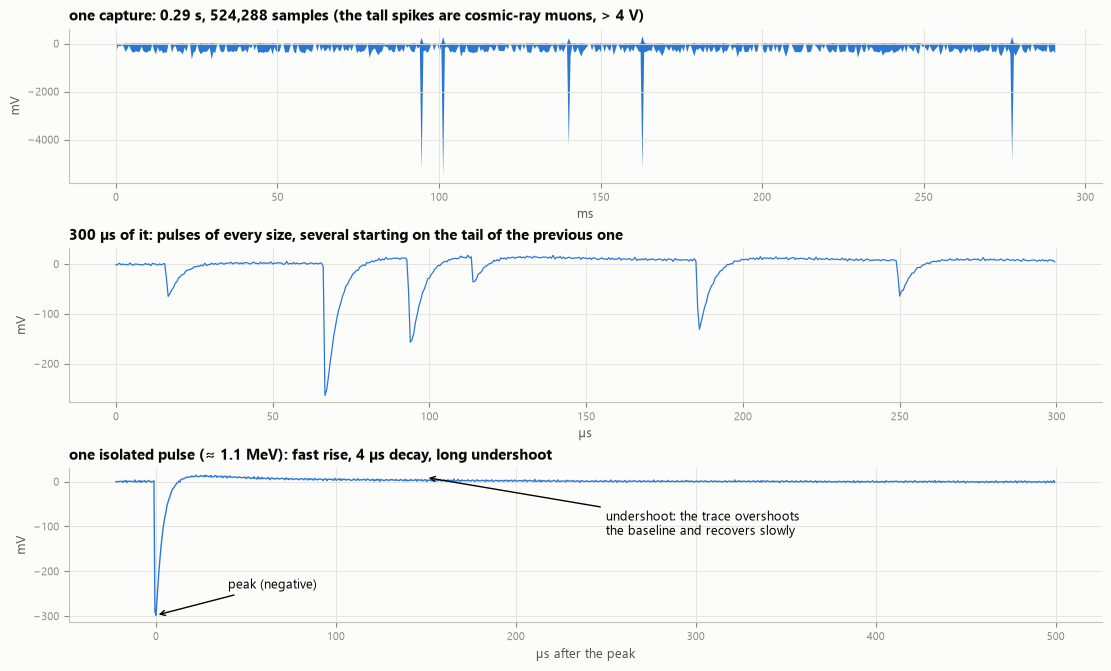

In [3]:
with store.CaptureStore(SRC_STORE) as s_:
    v_raw = s_.volts(0)
t_us = np.arange(v_raw.size) / FS * 1e6
fig, ax = P.figure(3, 1, height_per_row=2.2)
# 1: the whole capture (min/max envelope per 1000 samples)
blk = v_raw[: v_raw.size // 1000 * 1000].reshape(-1, 1000)
tb = np.arange(blk.shape[0]) * 1000 / FS * 1e3
ax[0,0].fill_between(tb, blk.min(1) * 1e3, blk.max(1) * 1e3, color=P.SERIES[0], lw=0)
ax[0,0].set_title("one capture: 0.29 s, 524,288 samples (the tall spikes are cosmic-ray muons, > 4 V)"); ax[0,0].set_xlabel("ms"); ax[0,0].set_ylabel("mV")
# 2: the busiest 300 µs (most pulse starts)
x_pos = signal.to_positive(v_raw) ; x_pos = x_pos - np.median(x_pos)
pk_ = signal.find_pulses(x_pos, signal.noise_sigma(x_pos), 8.0)
def busiest(idx, width, n):
    cnt = np.searchsorted(idx, idx + width) - np.arange(idx.size)
    ok = (idx > 2000) & (idx + width < n - 2000) & (x_pos[idx] < 1.0)
    return int(idx[ok][np.argmax(cnt[ok])]) - 30
a0 = busiest(pk_, 540, v_raw.size); sl = slice(a0, a0 + 540)
ax[1,0].plot(t_us[sl] - t_us[a0], v_raw[sl] * 1e3, color=P.SERIES[0], lw=0.9)
ax[1,0].set_title("300 µs of it: pulses of every size, several starting on the tail of the previous one"); ax[1,0].set_xlabel("µs"); ax[1,0].set_ylabel("mV")
# 3: one isolated pulse
iso_ = pk_[signal.isolated(pk_, 300, 900, x_pos.size)]
p0 = int(iso_[np.argmin(np.abs(x_pos[iso_] - 0.3))])
sl = slice(p0 - 40, p0 + 900)
ax[2,0].plot((np.arange(sl.start, sl.stop) - p0) / FS * 1e6, v_raw[sl] * 1e3, color=P.SERIES[0], lw=1)
ax[2,0].annotate("peak (negative)", xy=(0, v_raw[p0] * 1e3), xytext=(40, v_raw[p0] * 1e3 * 0.8), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax[2,0].annotate("undershoot: the trace overshoots\nthe baseline and recovers slowly", xy=(150, np.median(v_raw) * 1e3 + 8), xytext=(250, np.median(v_raw) * 1e3 - 120), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax[2,0].set_title("one isolated pulse (≈ 1.1 MeV): fast rise, 4 µs decay, long undershoot"); ax[2,0].set_xlabel("µs after the peak"); ax[2,0].set_ylabel("mV")
plt.show()

## 0.3 Step 1: from 7 MB of text to a compact file

The digitiser writes every capture as a text file, with one number per line. The first
step converts the numbers to exact integer ADC codes in a compressed binary file (lossless).
The processing then reduces it once more: from samples to **one row per pulse** (its time,
amplitude and quality flags). That event list is all later steps need.

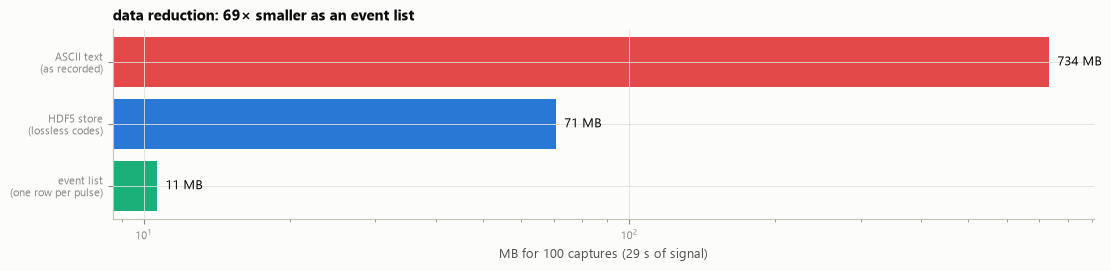

In [4]:
n_caps = 100
with store.CaptureStore(SRC_STORE) as s_:
    ns_ = s_.n_samples
sizes = {"ASCII text\n(as recorded)": 14 * ns_ * n_caps, "HDF5 store\n(lossless codes)": SRC_STORE.stat().st_size,
         "event list\n(one row per pulse)": (ROOT / "data/events/source_first100.h5").stat().st_size}
fig, ax = P.figure(1, 1, height_per_row=2.6)
names, vals = list(sizes), np.array(list(sizes.values())) / 1e6
ax[0,0].barh(names, vals, color=[P.SERIES[7], P.SERIES[0], P.SERIES[2]])
for i_, v_ in enumerate(vals):
    ax[0,0].text(v_, i_, f"  {v_:,.0f} MB" if v_ > 10 else f"  {v_:.1f} MB", va="center", fontsize=9)
ax[0,0].set_xscale("log"); ax[0,0].set_xlabel("MB for 100 captures (29 s of signal)"); ax[0,0].invert_yaxis()
ax[0,0].set_title(f"data reduction: {vals[0] / vals[2]:.0f}× smaller as an event list"); plt.show()

## 0.4 Step 2: removing interference

Besides pulses, the signal carries narrow **interference lines**: sine waves at fixed
frequencies, from power electronics nearby. Which lines are present changes from capture to
capture. In a frequency spectrum of the pulse-free signal they stand out as sharp spikes.
The program finds them, fits sine waves to the stretches between pulses, and subtracts
them.

**Why it matters:** interference adds to every pulse height, so it widens the peaks and
can trigger false pulses.

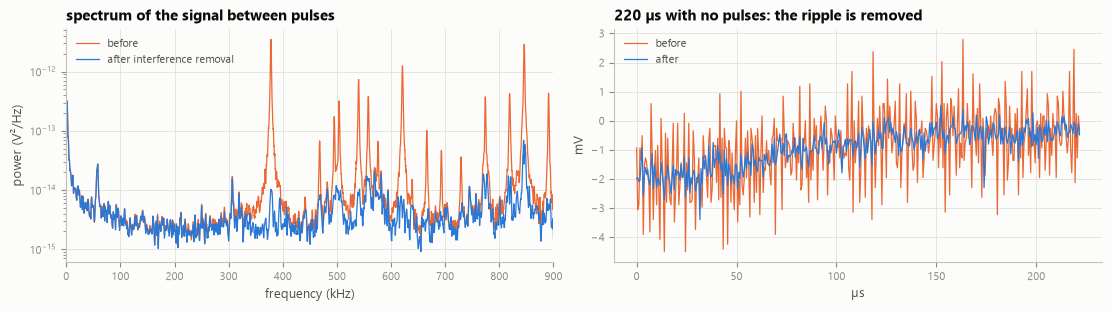

interference lines found and removed in this capture (kHz): [378.  441.  468.  495.  504.  540.  558.  576.  621.  639.  666.  693.  729.  774.  780.8 810.  819.  846.
 864.  870.5 891. ]
noise between pulses: 1.19 mV before, 0.51 mV after


In [5]:
from scipy.signal import welch
pz_d = baseline.design_from_template(Tp_raw := template.PulseTemplate.load(TEMPLATE))
def stage(**on):
    cfg_ = preprocess.PreprocessConfig(**{**dict(line_removal=False, pole_zero=False, baseline_tracker=False), **on})
    return preprocess.Preprocessor(FS, cfg_, pz_d if cfg_.pole_zero else None).process(v_raw)
import warnings as _w
with _w.catch_warnings():
    _w.simplefilter("ignore")
    x_0 = stage()                                           # polarity + offset only
    x_1 = stage(line_removal=True)                          # + interference removal
    x_2 = stage(line_removal=True, pole_zero=True, baseline_tracker=True)   # + pole-zero + baseline tracker
free_ = signal.pulse_free_mask(x_0.size, signal.find_pulses(x_0, signal.noise_sigma(x_0), 5.0), 20, 1500)
fig, ax = P.figure(1, 2, height_per_row=3.0)
for xx, lab, col in ((x_0, "before", P.SERIES[1]), (x_1, "after interference removal", P.SERIES[0])):
    seg = np.where(free_, xx, 0.0)
    f_, p_ = welch(seg, FS, nperseg=8192)
    ax[0,0].semilogy(f_ / 1e3, p_, color=col, lw=0.9, label=lab)
ax[0,0].set_xlim(0, 900); ax[0,0].set_xlabel("frequency (kHz)"); ax[0,0].set_ylabel("power (V²/Hz)"); ax[0,0].legend()
ax[0,0].set_title("spectrum of the signal between pulses")
q = np.flatnonzero(np.convolve(free_, np.ones(400), "valid") == 400)[0]
sl = slice(q, q + 400)
ax[0,1].plot(np.arange(400) / FS * 1e6, x_0[sl] * 1e3, color=P.SERIES[1], lw=0.9, label="before")
ax[0,1].plot(np.arange(400) / FS * 1e6, x_1[sl] * 1e3, color=P.SERIES[0], lw=0.9, label="after")
ax[0,1].set_xlabel("µs"); ax[0,1].set_ylabel("mV"); ax[0,1].legend(); ax[0,1].set_title("220 µs with no pulses: the ripple is removed")
plt.show()
pre_l = preprocess.Preprocessor(FS, preprocess.PreprocessConfig(pole_zero=False, baseline_tracker=False)); pre_l.process(v_raw)
print(f"interference lines found and removed in this capture (kHz): {np.round(np.sort(pre_l.info.line_freqs_hz) / 1e3, 1)}")
print(f"noise between pulses: {1e3*np.std(x_0[free_]):.2f} mV before, {1e3*np.std(x_1[free_]):.2f} mV after")

## 0.5 Step 3: restoring the baseline

Each pulse is followed by its slow undershoot, so a pulse that arrives shortly after another
one sits *below* zero. Measured from zero, it comes out too small. **Pole-zero correction**
is a digital filter that cancels the undershoot of every pulse exactly (it is designed from
the measured pulse shape). The **baseline tracker** then removes what is left of slow
drifts. After both, every pulse starts from zero, whatever came before it.

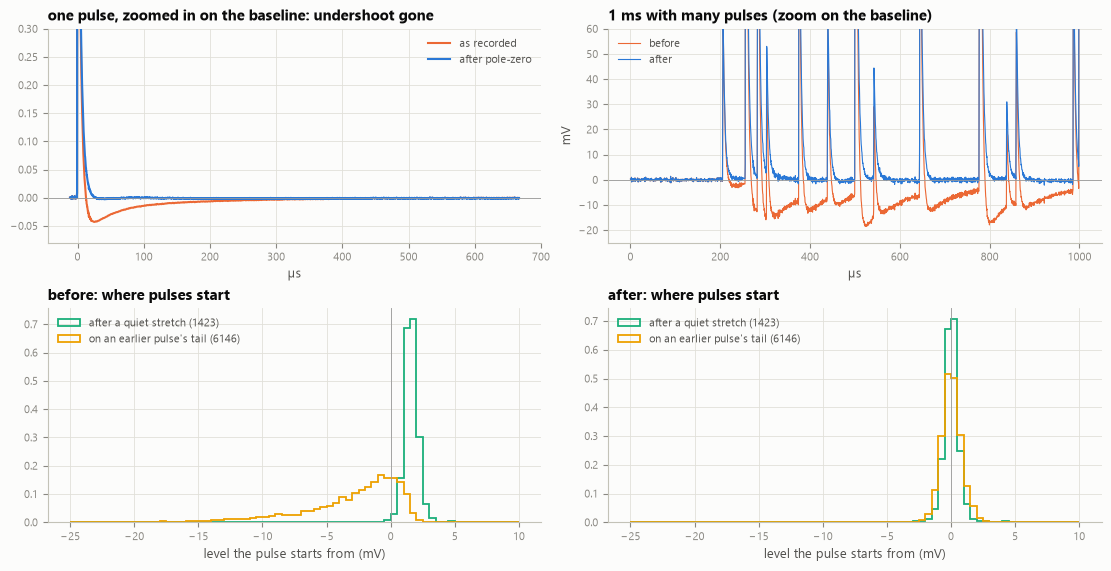

In [6]:
Tp_pz = baseline.filter_template(Tp_raw, pz_d.b, pz_d.a)
fig, ax = P.figure(2, 2, height_per_row=2.8)
tt = np.linspace(-20, 1200, 3000)
ax[0,0].plot(tt / FS * 1e6, Tp_raw(tt), color=P.SERIES[1], label="as recorded")
ax[0,0].plot(tt / FS * 1e6, Tp_pz(tt) / Tp_pz.shape.max(), color=P.SERIES[0], label="after pole-zero")
ax[0,0].axhline(0, color="#999", lw=0.6); ax[0,0].set_ylim(-0.08, 0.3); ax[0,0].set_xlabel("µs"); ax[0,0].legend()
ax[0,0].set_title("one pulse, zoomed in on the baseline: undershoot gone")
# a busy stretch
dens = np.convolve(np.isin(np.arange(x_0.size), pk_), np.ones(1800), "same")
c_ = int(np.argmax(dens[5000:-5000])) + 5000
sl = slice(c_ - 900, c_ + 900)
tus = np.arange(sl.stop - sl.start) / FS * 1e6
ax[0,1].plot(tus, x_1[sl] * 1e3, color=P.SERIES[1], lw=0.8, label="before")
ax[0,1].plot(tus, x_2[sl] * 1e3, color=P.SERIES[0], lw=0.8, label="after")
ax[0,1].axhline(0, color="#999", lw=0.6); ax[0,1].set_ylim(-25, 60); ax[0,1].set_xlabel("µs"); ax[0,1].set_ylabel("mV"); ax[0,1].legend()
ax[0,1].set_title("1 ms with many pulses (zoom on the baseline)")
# where does each pulse start? the signal 3 samples before its rise, before vs after correction
# (10 captures, pulses that follow another pulse within 60-400 samples vs pulses on a quiet baseline)
B = {"before": ([], []), "after": ([], [])}
with store.CaptureStore(SRC_STORE) as s_, _w.catch_warnings():
    _w.simplefilter("ignore")
    for ci in range(10):
        v_ = s_.volts(ci)
        xb = preprocess.Preprocessor(FS, preprocess.PreprocessConfig(pole_zero=False, baseline_tracker=False)).process(v_)
        xa = preprocess.Preprocessor(FS, preprocess.PreprocessConfig(), pz_d).process(v_)
        p_ = signal.find_pulses(xa, signal.noise_sigma(xa), 8.0)
        p_ = p_[(p_ > 2000) & (p_ < xa.size - 10)]
        g_ = np.r_[np.inf, np.diff(p_)]
        for lab, xx in (("before", xb), ("after", xa)):
            base = np.median(xx)
            B[lab][0].append(xx[p_ - 4][g_ > 900] - base); B[lab][1].append(xx[p_ - 4][(g_ > 60) & (g_ < 400)] - base)
bins = np.linspace(-25, 10, 71)
for k_, lab in enumerate(("before", "after")):
    clean_b, tail_b = (np.concatenate(v) * 1e3 for v in B[lab])
    ax[1,k_].hist(clean_b, bins, histtype="step", density=True, color=P.SERIES[2], lw=1.3, label=f"after a quiet stretch ({clean_b.size})")
    ax[1,k_].hist(tail_b, bins, histtype="step", density=True, color=P.SERIES[3], lw=1.3, label=f"on an earlier pulse's tail ({tail_b.size})")
    ax[1,k_].axvline(0, color="#999", lw=0.6)
    ax[1,k_].set_xlabel("level the pulse starts from (mV)"); ax[1,k_].legend(fontsize=8)
    ax[1,k_].set_title(f"{lab}: where pulses start")
plt.show()

The bottom row shows the level each pulse starts from. Before the correction (left), a
pulse that follows another one (yellow) starts up to 15 mV *below* zero, in the
undershoot. A height measured from zero then comes out too small, by an amount that depends
on what came before; for a 300 mV pulse that is up to ~5 %, comparable to the detector's
resolution. After the correction (right), every pulse starts from zero (both groups
centred, and as narrow as the noise).

## 0.6 Step 4: the expected pulse shape (template)

All pulses from the detector have the same shape; only their size differs. The program
learns this shape once: it lines up hundreds of isolated pulses with sub-sample precision
and averages them. This **template** is used to find pulses (0.7), to measure them, and to
separate overlapping ones (0.8).

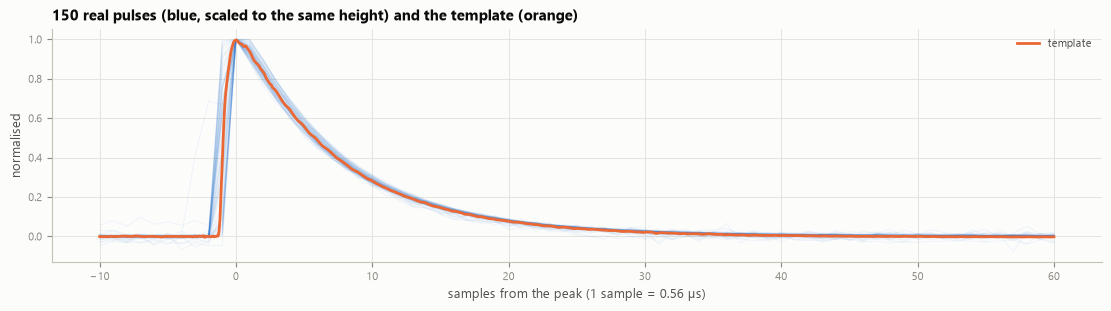

In [7]:
win_ = template.extract_windows(x_2, iso_[(iso_ > 100) & (iso_ < x_2.size - 200)][:300], 10, 60)
fig, ax = P.figure(1, 1, height_per_row=3.0)
tw = np.arange(-10, 61)
for w_ in win_[:150]:
    ax[0,0].plot(tw, w_ / w_.max(), color=P.SERIES[0], alpha=0.06, lw=0.8)
tf = np.linspace(-10, 60, 1000)
ax[0,0].plot(tf, Tp_pz(tf) / Tp_pz(np.array([0.0]))[0], color=P.SERIES[1], lw=2, label="template")
ax[0,0].set_xlabel("samples from the peak (1 sample = 0.56 µs)"); ax[0,0].set_ylabel("normalised"); ax[0,0].legend()
ax[0,0].set_title("150 real pulses (blue, scaled to the same height) and the template (orange)"); plt.show()

## 0.7 Step 5: finding the pulses

A simple threshold on the signal triggers on noise and misses pulses hidden in the tail of
a larger one. The program instead passes the signal through an **optimal filter**: it
compares every position with the template, weighted by how the noise behaves. The output
has a sharp peak wherever a pulse starts, with much less noise. Pulses are accepted above
5.5 times the filter's noise. Each accepted pulse's own response is then subtracted, so
that its side-lobes cannot be mistaken for more pulses (*successive cancellation*).

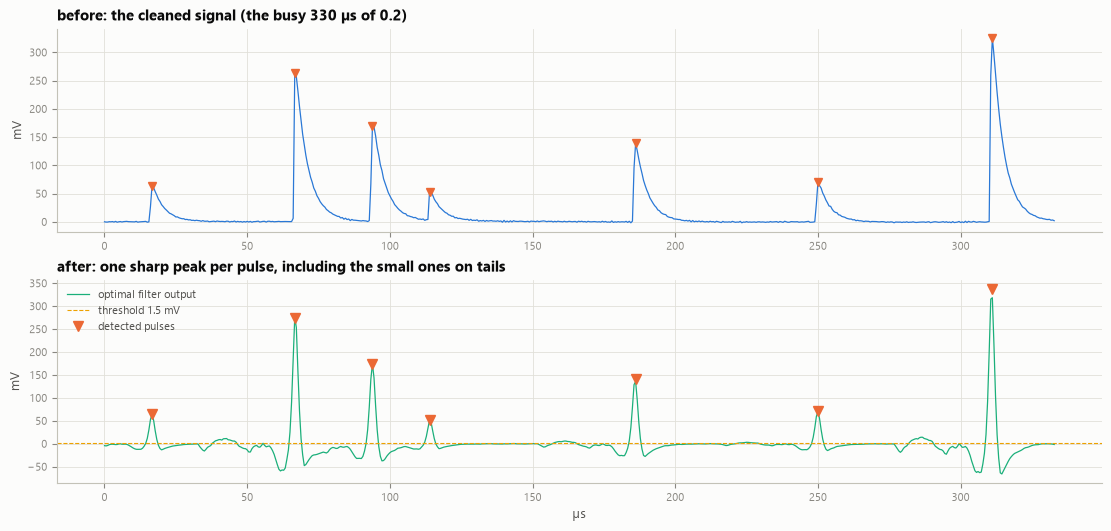

1357 pulses found in this capture (4659 per second); threshold 1.53 mV ≈ 6 keV


In [8]:
det_ = detect.Detector(Tp_pz)
y_f = det_.filter(x_2)
d_ = det_.detect(x_2)
b0 = a0                                                   # the busy stretch of 0.2
sl = slice(b0, b0 + 600)
tus = np.arange(sl.stop - sl.start) / FS * 1e6
fig, ax = P.figure(2, 1, height_per_row=2.6)
ax[0,0].plot(tus, x_2[sl] * 1e3, color=P.SERIES[0], lw=0.9)
ax[0,0].set_ylabel("mV"); ax[0,0].set_title("before: the cleaned signal (the busy 330 µs of 0.2)")
ax[1,0].plot(tus, y_f[sl] * 1e3, color=P.SERIES[2], lw=0.9, label="optimal filter output")
ax[1,0].axhline(d_.threshold_v * 1e3, color=P.SERIES[3], lw=0.8, ls="--", label=f"threshold {d_.threshold_v*1e3:.1f} mV")
inw = (d_.index >= sl.start) & (d_.index < sl.stop)
ax[1,0].plot((d_.index[inw] - sl.start) / FS * 1e6, d_.filter_amplitude[inw] * 1e3, "v", color=P.SERIES[1], ms=7, label="detected pulses")
for a_ in (ax[0,0],):
    a_.plot((d_.index[inw] - sl.start) / FS * 1e6, x_2[d_.index[inw]] * 1e3, "v", color=P.SERIES[1], ms=6)
ax[1,0].set_xlabel("µs"); ax[1,0].set_ylabel("mV"); ax[1,0].legend(fontsize=8)
ax[1,0].set_title("after: one sharp peak per pulse, including the small ones on tails"); plt.show()
print(f"{d_.index.size} pulses found in this capture ({d_.index.size / (x_2.size / FS):.0f} per second); "
      f"threshold {d_.threshold_v*1e3:.2f} mV ≈ {d_.threshold_v * 3760:.0f} keV")

## 0.8 Step 6: separating overlapping pulses (pile-up)

When two gamma rays arrive within a few microseconds, their pulses overlap. An analog MCA
sees one distorted pulse: it either records a wrong energy or rejects both. The program
fits a sum of templates to the cluster: one per pulse, each with its own height and
sub-sample arrival time. The fit uses the noise model, and the remainder (residual) is
checked for pulses that are still hidden.

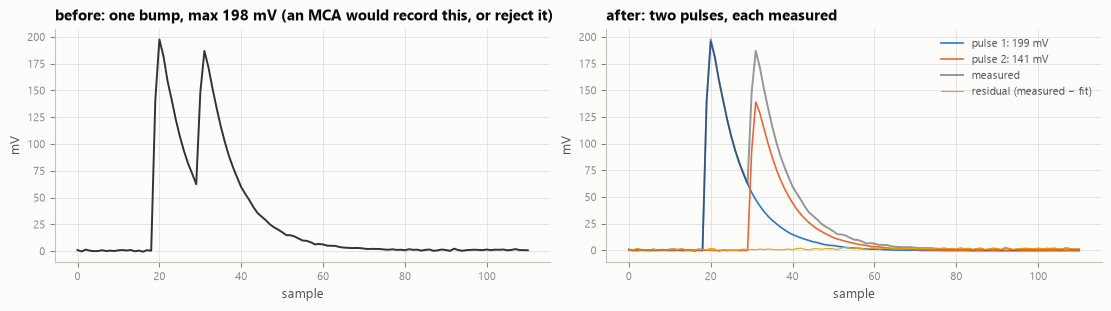

In [9]:
ef_ = events.EventFile(ROOT / "data/events/source_first100.h5")
ev_ = ef_.good()
pairs = ev_[(ev_["cluster_size"] == 2) & (ev_["gap_next"] > 5) & (ev_["gap_next"] < 14) & (ev_["amplitude"] > 0.15)]
pick = None
for r_ in pairs:
    if int(r_["cluster"]) in ef_._snip_by_cluster:
        pick = r_; break
cap_, start_, wav_ = ef_.snippet(int(pick["cluster"]))
members = ef_.events[ef_.events["cluster"] == pick["cluster"]]
ts = np.arange(wav_.size) + start_
fig, ax = P.figure(1, 2, height_per_row=3.0)
ax[0,0].plot(ts - start_, wav_ * 1e3, color="#333", lw=1.4, label="measured (clean signal)")
ax[0,0].set_title(f"before: one bump, max {wav_.max()*1e3:.0f} mV (an MCA would record this, or reject it)")
total = np.zeros(wav_.size)
for k_, m_ in enumerate(members):
    comp = m_["amplitude"] * Tp_pz(ts - (m_["index"] + m_["shift"])) / Tp_pz(np.array([0.0]))[0]
    total += comp
    ax[0,1].plot(ts - start_, comp * 1e3, color=P.SERIES[k_], lw=1.2, label=f"pulse {k_+1}: {m_['amplitude']*1e3:.0f} mV")
ax[0,1].plot(ts - start_, wav_ * 1e3, color="#333", lw=1.4, alpha=0.5, label="measured")
ax[0,1].plot(ts - start_, (wav_ - total) * 1e3, color=P.SERIES[3], lw=0.8, label="residual (measured − fit)")
ax[0,1].set_title("after: two pulses, each measured"); ax[0,1].legend(fontsize=8)
for a_ in ax[0]:
    a_.set_xlabel("sample"); a_.set_ylabel("mV")
plt.show()

## 0.9 The result: a sharper spectrum

Here are the same 20 captures counted two ways. The *naive* count takes the highest sample
of every bump in the raw signal, with no transformation. *This app* uses everything
above. Both are calibrated to keV the same way.

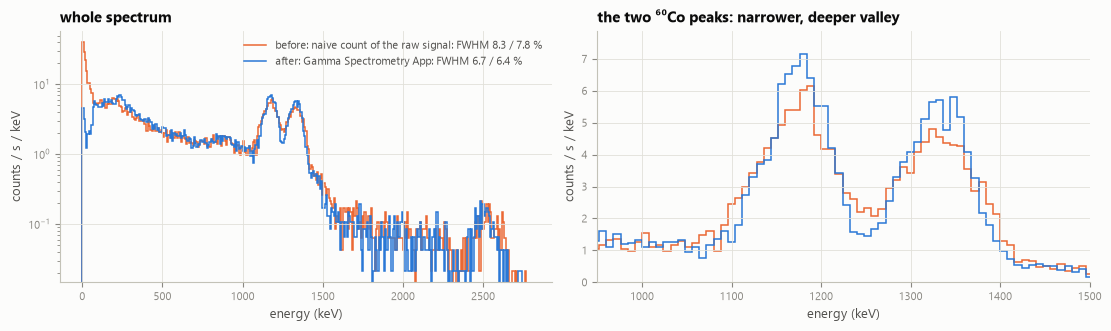

In [10]:
from gamma_spectrometry import benchmark, calibration, analysis
caps20 = range(20)
naive_ = benchmark.naive_chain(SRC_STORE, caps20)
gs_ = benchmark.pipeline_chain(ROOT / "data/events/source_first100.h5", caps20)
fig, ax = P.figure(1, 2, height_per_row=3.2)
edges = np.arange(0, 2800, 8.0)
top = 0
for ch_, col, lab in ((naive_, P.SERIES[1], "before: naive count of the raw signal"), (gs_, P.SERIES[0], "after: Gamma Spectrometry App")):
    m_ = benchmark.metrics(ch_)
    e_ = m_.pop("_energies")
    h_, _ = np.histogram(e_, edges)
    r_ = h_ / ch_.live_time_s / 8
    top = max(top, r_[(edges[:-1] > 950) & (edges[:-1] < 1500)].max())
    for a_ in ax[0]:
        a_.stairs(r_, edges, color=col, lw=1.1, label=f"{lab}: FWHM {m_['fwhm_pct'][0]:.1f} / {m_['fwhm_pct'][1]:.1f} %")
ax[0,0].set_yscale("log"); ax[0,0].set_title("whole spectrum"); ax[0,0].legend(fontsize=8)
ax[0,1].set_xlim(950, 1500); ax[0,1].set_ylim(0, top * 1.1); ax[0,1].set_title("the two ⁶⁰Co peaks: narrower, deeper valley")
for a_ in ax[0]:
    a_.set_xlabel("energy (keV)"); a_.set_ylabel("counts / s / keV")
plt.show()

The naive count has a large excess at low energy: noise and interference counted as pulses.
Its ⁶⁰Co peaks are 26 % wider, because pulses on tails are measured too low and
overlapping pulses are merged.

## 0.10 Step 7: from volts to keV, and removing the room background

The program finds known gamma lines (⁶⁰Co at 1173 and 1332 keV, their 2506 keV sum, and ⁴⁰K
at 1461 keV) and fits a straight line through them: energy = offset + gain × amplitude.
The room itself is radioactive (⁴⁰K in concrete, for example). A separate measurement
without the source is calibrated the same way and **subtracted**, per second of
measuring time.

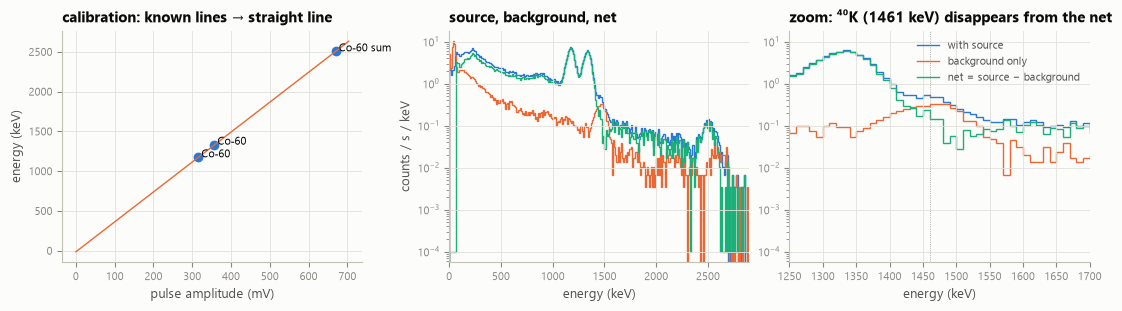

calibration: E = -12.9 + 3761.6 × A(V) keV; background run: +7.4 % gain (measured 5 days later)


In [11]:
src_ev = events.EventFile(ROOT / "data/events/source_first100.h5")
bkg_ev = events.EventFile(ROOT / "data/events/background.h5")
cal_s = calibration.calibrate(src_ev.good()["amplitude"], "source")
cal_b = calibration.calibrate(bkg_ev.good()["amplitude"], "background", reference=cal_s)
fig, ax = P.figure(1, 3, height_per_row=3.0)
pts = [p_ for p_ in cal_s.points if p_.accepted]
A_ = np.array([p_.amplitude_v for p_ in pts]); E_ = np.array([p_.energy_kev for p_ in pts])
ax[0,0].plot(A_ * 1e3, E_, "o", color=P.SERIES[0])
for p_ in pts:
    ax[0,0].annotate(f" {p_.label}", (p_.amplitude_v * 1e3, p_.energy_kev), fontsize=8)
aa = np.linspace(0, A_.max() * 1.05, 10)
ax[0,0].plot(aa * 1e3, cal_s.energy(aa), color=P.SERIES[1], lw=1)
ax[0,0].set_xlabel("pulse amplitude (mV)"); ax[0,0].set_ylabel("energy (keV)"); ax[0,0].set_title("calibration: known lines → straight line")
ed = np.arange(0, 3000, 10.0)
S_ = analysis.energy_spectrum(cal_s.energy(src_ev.good()["amplitude"]), src_ev.live_time_s, ed)
B_ = analysis.energy_spectrum(cal_b.energy(bkg_ev.good()["amplitude"]), bkg_ev.live_time_s, ed)
N_ = analysis.subtract(S_, B_)
for a_, lo, hi, title in ((ax[0,1], 0, 2900, "source, background, net"), (ax[0,2], 1250, 1700, "zoom: ⁴⁰K (1461 keV) disappears from the net")):
    a_.stairs(S_.rate / 10, ed, color=P.SERIES[0], label="with source")
    a_.stairs(B_.rate / 10, ed, color=P.SERIES[1], label="background only")
    a_.stairs(np.clip(N_.rate / 10, 1e-4, None), ed, color=P.SERIES[2], label="net = source − background")
    a_.set_xlim(lo, hi); a_.set_yscale("log"); a_.set_xlabel("energy (keV)"); a_.set_title(title)
ax[0,1].set_ylabel("counts / s / keV"); ax[0,2].legend(fontsize=8); ax[0,2].axvline(1460.8, color="#999", lw=0.6, ls=":")
plt.show()
print(f"calibration: E = {cal_s.coeffs[0]:.1f} + {cal_s.coeffs[1]:.1f} × A(V) keV; "
      f"background run: {100*(cal_b.coeffs[1]/cal_s.coeffs[1]-1):+.1f} % gain (measured 5 days later)")

## 0.11 Why a shaping amplifier struggles at high rates

An analog shaping amplifier turns each 4 µs pulse into a smooth bump. The bump averages
out noise, but it is wide: about 10 µs at its base for a 1 µs CR-RC⁴ shaper, against about
2 µs for the optimal filter's peak. The wider the bump, the more often two of them overlap
at 4,500 pulses/s; an MCA must then reject both, or record a wrong energy. The same stretch
of signal is shown through both.

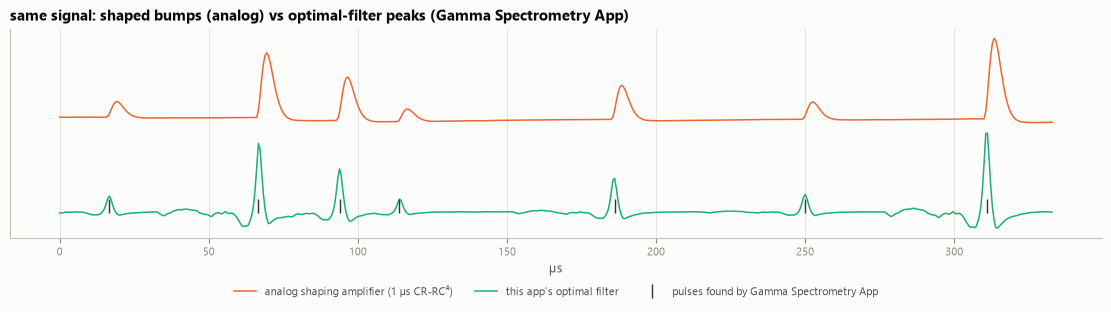

In [12]:
sh_ = benchmark.shaping_amplifier(x_1, 1 / FS, tau_shaping=1e-6)
sl = slice(b0, b0 + 600)
tus = np.arange(sl.stop - sl.start) / FS * 1e6
fig, ax = P.figure(1, 1, height_per_row=3.0)
ax[0,0].plot(tus, sh_[sl] / sh_[sl].max(), color=P.SERIES[1], lw=1.1, label="analog shaping amplifier (1 µs CR-RC⁴)")
ax[0,0].plot(tus, y_f[sl] / y_f[sl].max() - 1.2, color=P.SERIES[2], lw=1.1, label="this app's optimal filter")
ax[0,0].plot((d_.index[inw] - sl.start) / FS * 1e6, np.full(inw.sum(), 0.08) - 1.2, "|", color="#333", ms=10, label="pulses found by Gamma Spectrometry App")
ax[0,0].set_yticks([]); ax[0,0].set_xlabel("µs"); ax[0,0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax[0,0].set_title("same signal: shaped bumps (analog) vs optimal-filter peaks (Gamma Spectrometry App)"); plt.show()

## 0.12 Live input: processing a stream in overlapping frames

For live use, the signal arrives continuously. The program cuts it into **frames** of
0.15 s. Each frame carries some extra signal before it (so the filters have settled) and
after it (so the last pulses are complete). Each frame is processed exactly like a capture,
and only the pulses in its middle part (the *core*) are kept. Frames are independent, so
several are processed in parallel. If the PC falls behind a live source, a frame is
skipped and counted as dead time.

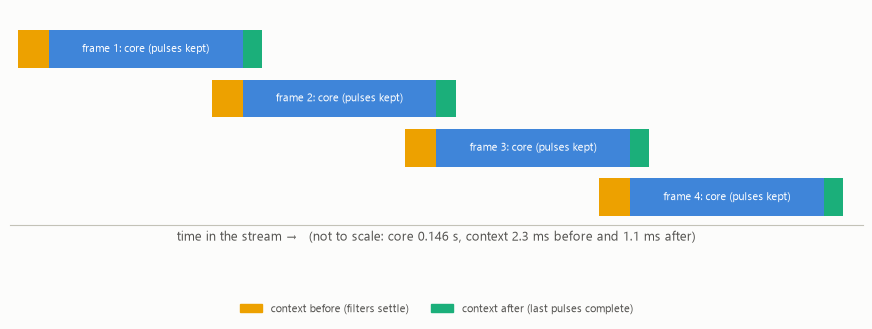

In [13]:
fig, ax = plt.subplots(figsize=(11, 2.8))
core_, pre_, post_ = 10.0, 1.6, 1.0                      # schematic: the real contexts are 1.6 % and 0.8 % of a core
for k_ in range(4):
    c0, y0 = k_ * core_, (3 - k_) * 0.55
    ax.add_patch(mpatches.Rectangle((c0 - pre_, y0), pre_, 0.42, fc=P.SERIES[3]))
    ax.add_patch(mpatches.Rectangle((c0, y0), core_, 0.42, fc=P.SERIES[0], alpha=0.9))
    ax.add_patch(mpatches.Rectangle((c0 + core_, y0), post_, 0.42, fc=P.SERIES[2]))
    ax.text(c0 + core_ / 2, y0 + 0.21, f"frame {k_+1}: core (pulses kept)", ha="center", va="center", color="white", fontsize=8)
ax.set_xlim(-2, 4 * core_ + 2); ax.set_ylim(-0.1, 2.3); ax.set_yticks([]); ax.set_xticks([])
ax.set_xlabel("time in the stream →   (not to scale: core 0.146 s, context 2.3 ms before and 1.1 ms after)")
ax.legend(handles=[mpatches.Patch(color=P.SERIES[3], label="context before (filters settle)"),
                   mpatches.Patch(color=P.SERIES[2], label="context after (last pulses complete)")], fontsize=8,
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
for s_ in ("top", "right", "left"):
    ax.spines[s_].set_visible(False)
plt.show()

## 0.13 Checking against the truth: the simulator

With real data, nobody knows the true energy of each pulse. The built-in **simulator**
makes a realistic signal where every pulse is known, so the result can be checked: how many
pulses were found, how accurately they were measured, and how many were invented.

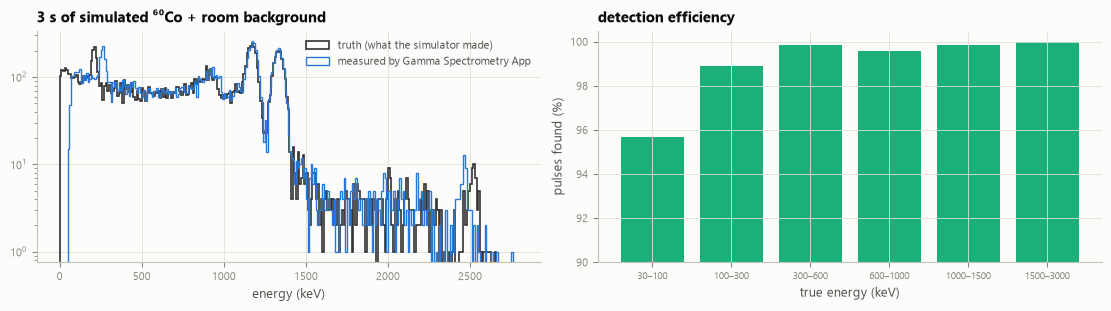

13269 true pulses, 13098 detected; 13 false /s; close pairs resolved 99.6 %; amplitude bias +0.50 %


In [14]:
sim_src = sources.SimulationSource(simulate.SimConfig(seed=11), duration_s=3.0)
simulate.analytic_template().save(TMP / "t_tour.h5")
stream.process_stream(sim_src, TMP / "t_tour.h5", TMP / "tour_events.h5", pipeline.PipelineConfig(),
                      stream.StreamConfig(update_s=0), workers=1, verbose=False, overwrite=True)
simulate.save_truth(TMP / "tour_truth.h5", sim_src.sim.truth_table(), sim_src.sim.cfg)
truth_ = simulate.load_truth(TMP / "tour_truth.h5"); found_ = events.EventFile(TMP / "tour_events.h5").good()
chk_ = simulate.compare_to_truth(TMP / "tour_events.h5", TMP / "tour_truth.h5")
fig, ax = P.figure(1, 2, height_per_row=3.0)
edges = np.arange(0, 2800, 10.0)
ax[0,0].hist(truth_["energy_kev"], edges, histtype="step", color="#333", lw=1.2, label="truth (what the simulator made)")
cal_sim = calibration.calibrate(found_["amplitude"], "source")
ax[0,0].hist(cal_sim.energy(found_["amplitude"]), edges, histtype="step", color=P.SERIES[0], lw=1.0, label="measured by Gamma Spectrometry App")
ax[0,0].set_yscale("log"); ax[0,0].set_xlabel("energy (keV)"); ax[0,0].legend(fontsize=8); ax[0,0].set_title("3 s of simulated ⁶⁰Co + room background")
eff_ = [e_ for e_ in chk_["efficiency_by_energy"] if e_["efficiency"] is not None]
ax[0,1].bar([f"{e_['energy_kev'][0]}–{e_['energy_kev'][1]}" for e_ in eff_], [100 * e_["efficiency"] for e_ in eff_], color=P.SERIES[2])
ax[0,1].set_ylim(90, 100.5); ax[0,1].set_ylabel("pulses found (%)"); ax[0,1].set_xlabel("true energy (keV)")
ax[0,1].set_title("detection efficiency"); ax[0,1].tick_params(axis="x", labelsize=7)
plt.show()
print(f"{chk_['true_pulses']} true pulses, {chk_['detected']} detected; {chk_['false_rate_cps']:.0f} false /s; "
      f"close pairs resolved {100*chk_['close_pairs_resolved']:.1f} %; amplitude bias {chk_['amplitude_bias_pct']:+.2f} %")

## 0.14 The whole program, in one line per step

| Step | In | Out | Part |
|---|---|---|---|
| Ingest | ASCII capture files | lossless binary store | A |
| Characterise | isolated pulses, noise | template, pulse model, noise spectrum | B |
| Clean | raw samples | interference removed, baseline at zero | C |
| Detect | clean signal | pulse positions, first amplitudes | D |
| Resolve pile-up | clusters of pulses | one amplitude and time per pulse | E |
| Calibrate, subtract | amplitudes of two runs | keV spectra, net spectrum, line rates | G |
| Benchmark | the same pulses | comparison with a naive count and an analog chain | H |
| Configure, run | a run file (or the app) | all of the above, chosen step by step | I |
| Stream, simulate | live or simulated signal | the same, continuously; checked against truth | J |

The parts below show every function behind these steps, in the order it is called.

---
# Part A: Ingestion (step 1)

## A1. `rawio.read_header(path)`

**Called by:** `build_index` (for every file) and `read_raw_file`.
**Input:** a capture file path. **Output:** a `RawHeader`.

It reads only the first three lines (`Creation`, `Signals`, `Dt`), splits each at the first
colon, and converts: the timestamp with `datetime.fromisoformat`, the sample count as an
integer, and `Dt` with its unit (`ms` → × 10⁻³ s). It also records how many bytes the header
occupies, so the samples can be read starting right after it.

In [15]:
path = RAW / "raw_data_0.txt"
print("input: first 3 lines of", path.name)
with open(path, "rb") as f:
    for _ in range(3): print("   ", f.readline())
h = rawio.read_header(path)
print("\noutput:", h)
print("duration_s =", h.duration_s, "  time_s =", h.time_s)

input: first 3 lines of raw_data_0.txt
    b'Creation: 2021-08-26 13:34:48.617564\n'
    b'Signals:  524288\n'
    b'Dt:       5.555555555555556e-04 ms\n'

output: RawHeader(path=WindowsPath('D:/GammaSpectroscopy/ADC_raw_output/raw_data_0.txt'), file_number=0, created=datetime.datetime(2021, 8, 26, 13, 34, 48, 617564), n_samples=524288, dt_s=5.555555555555555e-07, header_bytes=89)
duration_s = 0.2912711111111111   time_s = 1629984888.617564


## A2. `rawio.parse_samples(body)` → `_parse_fixed_width(body)`

**Input:** the bytes after the header. **Output:** float64 volts.

Every sample line has exactly 14 bytes: `+d.dddddde-dd\n`. Instead of parsing 524,288
strings one at a time, the bytes are viewed as a **matrix with 14 columns** (one row per
line) and decoded column-wise with array arithmetic:

$$\text{mantissa} = \sum_{i=0}^{6} d_i\,10^{6-i},\qquad
\text{exponent} = \pm(10e_1 + e_2) - 6,\qquad v = \pm\,\text{mantissa}\cdot 10^{\text{exponent}}$$

where $d_i$ are the 7 mantissa digits (column 1, then columns 3–8; column 2 is the `.`).
Digits are bytes minus `ord('0')` = 48. The function first checks every fixed column
(`.` at 2, `e` at 9, newline at 13, signs, digits). If anything does not match, it returns
`None`, and `parse_samples` falls back to a generic float parser.

In [16]:
raw = path.read_bytes()
body = raw[h.header_bytes:]
a = np.frombuffer(body, dtype=np.uint8).reshape(-1, 14)
print("input bytes, first 2 lines:", body[:28])
print("as a 14-column uint8 matrix (row 0):", a[0], "->", bytes(a[0]))
d = a[0, [1, 3, 4, 5, 6, 7, 8]].astype(int) - 48
print("mantissa digits:", d, " exponent sign:", chr(a[0, 10]), " exponent digits:", a[0, 11:13] - 48)
v = rawio.parse_samples(body)
print("\noutput volts:", v, " count:", v.size)

input bytes, first 2 lines: b'+3.390868e-04\n+2.458379e-03\n'
as a 14-column uint8 matrix (row 0): [ 43  51  46  51  57  48  56  54  56 101  45  48  52  10] -> b'+3.390868e-04\n'
mantissa digits: [3 3 9 0 8 6 8]  exponent sign: -  exponent digits: [0 4]

output volts: [0.00034 0.00246 0.00229 0.00034 ... 0.00415 0.00424 0.00644 0.00704]  count: 524288


## A3. `rawio.volts_to_codes(volts, lsb)`

**Input:** volts and the ADC step (LSB = 84.771697 µV). **Output:** int32 ADC codes.

$$\text{code} = \operatorname{rint}(v/\text{LSB}),\qquad
\text{residual} = \max|v/\text{LSB} - \text{code}|$$

The printed values are codes × LSB rounded to 7 significant digits, so the residual is
tiny (≤ 0.006 LSB). If it exceeds 0.02 LSB the file is not on this ADC grid and the
function raises an error. This check proves the conversion loses nothing.

In [17]:
codes = rawio.volts_to_codes(v, rawio.DEFAULT_LSB_VOLTS)
x = v / rawio.DEFAULT_LSB_VOLTS
print("input  volts :", v[:6])
print("v / LSB      :", x[:6])
print("output codes :", codes[:6], codes.dtype)
print("max residual :", np.max(np.abs(x - codes)), "LSB   (code range", codes.min(), "to", codes.max(), ")")

input  volts : [ 3.39087e-04  2.45838e-03  2.28884e-03  3.39087e-04  7.62945e-04 -8.47717e-05]
v / LSB      : [ 4. 29. 27.  4.  9. -1.]
output codes : [ 4 29 27  4  9 -1] int32
max residual : 0.005473064913530834 LSB   (code range -65103 to 3783 )


## A4. `rawio.read_raw_file(path, lsb)`
Combines A1–A3: header → seek past it → parse → check the count → codes (or volts if
`lsb=None`). This is what each conversion worker runs.

In [18]:
h2, c2 = rawio.read_raw_file(path)
print("output:", h2.n_samples, "samples; codes", c2[:5], "; identical to A3:", np.array_equal(c2, codes))

output: 524288 samples; codes [ 4 29 27  4  9] ; identical to A3: True


## A5. `rawio.estimate_lsb(volts)` (for unknown hardware)

**Input:** volts. **Output:** the ADC step.

1. Near zero the printed values keep full precision, so the spacing between the smallest
   distinct |values| gives a first guess.
2. Refine with least squares over progressively larger values (bound × 8 each pass):
   $$\text{LSB} \leftarrow \frac{\sum_i v_i k_i}{\sum_i k_i^2},\qquad k_i = \operatorname{rint}(v_i/\text{LSB})$$
   Each pass only includes values where rounding to the right code is still unambiguous.

In [19]:
print("estimated LSB:", rawio.estimate_lsb(v), " built-in:", rawio.DEFAULT_LSB_VOLTS)

estimated LSB: 8.47716969775423e-05  built-in: 8.4771697e-05


## A6. `rawio.build_index(directory)` and `write_index_csv`

**Input:** a folder. **Output:** all headers **sorted by timestamp** (the file numbers in
the 2021 data are scrambled relative to time; see ADR-0002).

In [20]:
idx = rawio.build_index(RAW)
print("captures:", len(idx))
for hh in idx[:5]:
    print(f"   file {hh.file_number:5d}  created {hh.created}")
print("file numbers of the first 8 in time order:", [hh.file_number for hh in idx[:8]])

captures: 4786
   file     0  created 2021-08-26 13:34:48.617564
   file   302  created 2021-08-26 13:34:50.906028
   file   404  created 2021-08-26 13:34:53.152647
   file  1774  created 2021-08-26 13:34:55.175131
   file  2883  created 2021-08-26 13:34:57.018127
file numbers of the first 8 in time order: [0, 302, 404, 1774, 2883, 3020, 3156, 3293]


## A7. `store.convert(headers, out_path)` and `store.CaptureStore`

**Input:** headers (time order). **Output:** one HDF5 file: `/codes` (int32, one row per
capture, gzip + shuffle), `/index/*` (time, file number, path) and attributes (LSB, Δt).
Parsing runs in parallel worker processes (`_read_codes`); one process writes.

`CaptureStore(path)` reads it back: `codes(i)`, `volts(i) = codes × LSB`, `live_time_s`.
(Here we open the store built earlier rather than converting again.)

In [21]:
with store.CaptureStore(SRC_STORE) as s:
    print("captures:", len(s), " samples/capture:", s.n_samples, " LSB:", s.lsb_volts, " dt:", s.dt_s)
    print("live time:", s.live_time_s, "s")
    print("capture 0 source:", s.source[0], " file number:", s.file_number[0])
    print("codes(0)[:5] =", s.codes(0)[:5], " identical to the text file:", np.array_equal(s.codes(0), codes))
    print("volts(0)[:5] =", s.volts(0)[:5])

captures: 100  samples/capture: 524288  LSB: 8.4771697e-05  dt: 5.555555555555555e-07
live time: 29.12711111111111 s
capture 0 source: ADC_raw_output\raw_data_0.txt  file number: 0
codes(0)[:5] = [ 4 29 27  4  9]  identical to the text file: True
volts(0)[:5] = [0.00034 0.00246 0.00229 0.00034 0.00076]


---
# Part B: Characterisation (step 2)

We use capture 1 of the ⁶⁰Co run as the running example.

## B1. `signal.to_positive(volts, polarity=-1)`
Multiplies by −1, so pulses point up. Then the capture median is subtracted (in
`characterize.scan`).

In [22]:
with store.CaptureStore(SRC_STORE) as s:
    volts1 = s.volts(1)
x1 = signal.to_positive(volts1)
x1 = x1 - np.median(x1)
print("input min/max:", volts1.min(), volts1.max(), " -> output min/max:", x1.min(), x1.max())

input min/max: -4.353196184344 0.225068855535  -> output min/max: -0.223882051777 4.354382988102


## B2. `signal.robust_sigma(x)` and `signal.noise_sigma(x)`

* `robust_sigma`: $\hat\sigma = 1.4826\cdot\operatorname{median}|x-\operatorname{median}(x)|$.
  For Gaussian noise the median absolute deviation is 0.6745 σ (1/0.6745 = 1.4826).
  Outliers such as pulses barely move a median.
* `noise_sigma`: robust σ of the **first differences** divided by √2. For white noise
  $\operatorname{Var}(x_n - x_{n-1}) = 2\sigma^2$. Differencing removes slow baseline changes
  and the undershoot, and pulses are rare outliers. It uses the central 131,072 samples.

In [23]:
print("plain std           :", x1.std())
print("robust_sigma(x)     :", signal.robust_sigma(x1))
print("noise_sigma(x)      :", signal.noise_sigma(x1))

plain std           : 0.027680427398760744
robust_sigma(x)     : 0.0027650153953883995
noise_sigma(x)      : 0.0014219353717558835


## B3. `signal.edge_signal(x, gap=2, avg=3)`

$$d[n] = x[n] - \tfrac{1}{3}\left(x[n-4] + x[n-3] + x[n-2]\right)$$

This is the rise relative to a short average ending 2 samples earlier. The pulse rises in
1–2 samples, so a half-risen sample stays out of the reference. On a slowly falling tail
d is small or negative, so the trigger does not fire on decays. The average is computed
with a cumulative sum (cs[i+3] − cs[i]) / 3.

In [24]:
sig1 = signal.noise_sigma(x1)
pk = signal.find_pulses(x1, sig1, 8)
p0 = int(pk[10])
e1 = signal.edge_signal(x1)
seg = slice(p0 - 6, p0 + 8)
print("x[n] around a pulse     :", np.round(x1[seg], 4))
print("edge_signal d[n] (same) :", np.round(e1[seg], 4))

x[n] around a pulse     : [ 0.0001 -0.0019 -0.0006 -0.0019 -0.0007  0.08    0.0947  0.082   0.0739  0.065   0.0546  0.0473  0.0406
  0.0343]
edge_signal d[n] (same) : [ 0.0013 -0.0001  0.0005 -0.001   0.0001  0.0815  0.0958  0.0562  0.0159 -0.0205 -0.0289 -0.0263 -0.0239
 -0.0213]


## B4. `signal.find_pulses(x, sigma, threshold)`

Fires where the edge signal exceeds `threshold` × its noise. Its noise is
$\sigma\sqrt{1 + 1/3}$ (one sample minus a 3-sample average). Each trigger is moved to
the highest sample within the next 4 samples, the peak.

In [25]:
print("input: sigma =", sig1, " threshold = 8")
print("output: ", pk.size, "pulse peaks; first:", pk[:8])
print("rate:", pk.size / (x1.size / FS), "per second")

input: sigma = 0.0014219353717558835  threshold = 8
output:  1215 pulse peaks; first: [ 454  967 1398 2103 2155 2293 2633 3700]
rate: 4171.3714599609375 per second


## B5. `signal.isolated(peaks, pre, post, n)` and `signal.pulse_free_mask(n, peaks, pre, post)`

* `isolated`: True where no other pulse lies within `pre` samples before or `post` after
  (and the window fits in the capture). Uses the gaps `diff(peaks)`.
* `pulse_free_mask`: True for samples at least `pre` before and `post` after every pulse.
  It marks +1 at each pulse's start of exclusion and −1 at its end, takes a cumulative sum,
  and keeps samples where the sum is 0. That is linear time, with no loops.

In [26]:
iso = signal.isolated(pk, 300, 300, x1.size)
free = signal.pulse_free_mask(x1.size, pk, 20, 1500)
print("isolated (±300):", iso.sum(), "of", pk.size, "   pulse-free samples (20 before, 1500 after):", free.mean().round(3))

isolated (±300): 312 of 1215    pulse-free samples (20 before, 1500 after): 0.026


## B6. `template.extract_windows(x, peaks, pre, post)`
One row per pulse: `x[p-pre : p+post+1]`, built with a single fancy-index (`peaks[:,None] + arange`).

In [27]:
W = template.extract_windows(x1, pk[iso], 40, 300)
print("output shape:", W.shape, " (pulses × samples); row 0 around the peak:", np.round(W[0, 38:44], 4))

output shape: (312, 341)  (pulses × samples); row 0 around the peak: [0.001  0.1317 0.2491 0.2326 0.2052 0.1795]


## B7. `template.fit_pulses(windows, template, pre, ...)`

Fits each window as $w(j) = A\,s(j - \delta) + b$ over $j \in [-10, 60]$
(A = amplitude, δ = sub-sample peak position, b = baseline).

For a **fixed δ** the model is linear in A and b. Least squares has a closed form: with
$S_{ss}=\sum s^2,\ S_s=\sum s,\ S_{sy}=\sum s y,\ S_y=\sum y,\ n$ samples,

$$A = \frac{n S_{sy} - S_s S_y}{n S_{ss} - S_s^2},\qquad
b = \frac{S_{ss} S_y - S_s S_{sy}}{n S_{ss} - S_s^2},\qquad
\text{SSE} = \sum y^2 - A S_{sy} - b S_y$$

So: evaluate this for 33 trial δ ∈ [−1, 1] (all pulses at once with one matrix product
$Y S^T$), take the best δ, refine it with a parabola through the three SSE values around
the minimum, then solve exactly at the refined δ. With `fit_baseline=False` (used after
baseline restoration) b = 0 and $A = S_{sy}/S_{ss}$.

In [28]:
T = template.PulseTemplate.load(TEMPLATE)
f = template.fit_pulses(W[:5].astype(float), T, 40)
print("input : 5 windows; peak samples", np.round(W[:5, 40], 4))
print("output: amplitude", np.round(f.amplitude, 4))
print("        shift δ  ", np.round(f.shift, 3), "(samples)")
print("        baseline ", np.round(f.baseline * 1e3, 3), "mV;  rms", np.round(f.rms * 1e3, 3), "mV")

input : 5 windows; peak samples [0.2491 0.1489 0.0821 0.223  0.2497]
output: amplitude [0.2512 0.1539 0.081  0.2245 0.2479]
        shift δ   [-0.075 -0.557  0.017 -0.029 -0.09 ] (samples)
        baseline  [ 2.283  1.469  1.179 -0.232  2.397] mV;  rms [1.397 1.301 1.224 1.484 1.158] mV


## B8. `template.build_template(windows, pre)`, with `_stack`, `_recentre`, `equalize_phase`

Pulses arrive at random sampling phases. Stacking many pulses at their *true* sub-sample
times samples the shape on a grid much finer than the ADC's (equivalent-time sampling).
Each iteration:

1. **`_stack`**: put every normalised sample $(w-b)/A$ at time $t = j - \delta$ into bins of
   1/16 sample; weighted average (weight $A^2$, the inverse variance of a normalised
   sample); light smoothing (none within ±3 samples of the peak); pre-pulse level set to 0.
2. **`_recentre`**: a parabola through the top three points finds the continuous maximum;
   shift it to t = 0 and scale it to 1.
3. **`fit_pulses`** with the new template; drop fits with rms > 3 × median (hidden pile-up).
4. **`equalize_phase`**: the true phases $\varphi = \delta \bmod 1$ are uniform, so map the
   fitted ones through their empirical CDF, $\varphi_i \to (\text{rank}_i + 0.5)/N$.
   Without this, a template warped inside each sample period plus correspondingly warped δ
   fit almost equally well (ADR-0004).

It stops when the template changes by less than 5 × 10⁻⁴ rms. Here we run it on the
isolated pulses of the background run (long isolation shows the whole undershoot).

In [29]:
with store.CaptureStore(BKG_STORE) as s:
    wins = []
    for i in range(20, 50):
        xb = signal.to_positive(s.volts(i)); xb = xb - np.median(xb)
        sb = signal.noise_sigma(xb); pb = signal.find_pulses(xb, sb, 5)
        ok = signal.isolated(pb, 1500, 1500, xb.size) & (xb[pb] > 30 * sb) & (xb[pb] < 4)
        wins.append(template.extract_windows(xb, pb[ok], 40, 1500))
Wb = np.concatenate(wins)
print("input:", Wb.shape[0], "isolated pulses, windows of", Wb.shape[1], "samples")
Tb, fb, used = template.build_template(Wb, 40, resolution=16, verbose=True)
print("output: template with", Tb.shape.size, "points at 1/16 sample, t from", Tb.t_start, "to", round(Tb.t_end, 2))
print("template at t = -2, -1, 0, 1, 5, 46 samples:", np.round(Tb(np.array([-2., -1, 0, 1, 5, 46])), 4))

input: 866 isolated pulses, windows of 1541 samples
  iter 0: used 812/866, median rms 0.00434 V, max change inf
  iter 1: used 783/866, median rms 0.00208 V, max change 9.07e-03
  iter 2: used 782/866, median rms 0.00206 V, max change 5.99e-04
  iter 3: used 782/866, median rms 0.00207 V, max change 1.36e-04
output: template with 24608 points at 1/16 sample, t from -38.9375 to 1499.0
template at t = -2, -1, 0, 1, 5, 46 samples: [-0.0011  0.2404  0.9995  0.9473  0.5359 -0.0427]


equalize_phase example: fitted phases [0.1  0.15 0.18 0.5  0.52 0.9 ] -> [0.083 0.25  0.417 0.583 0.75  0.917]


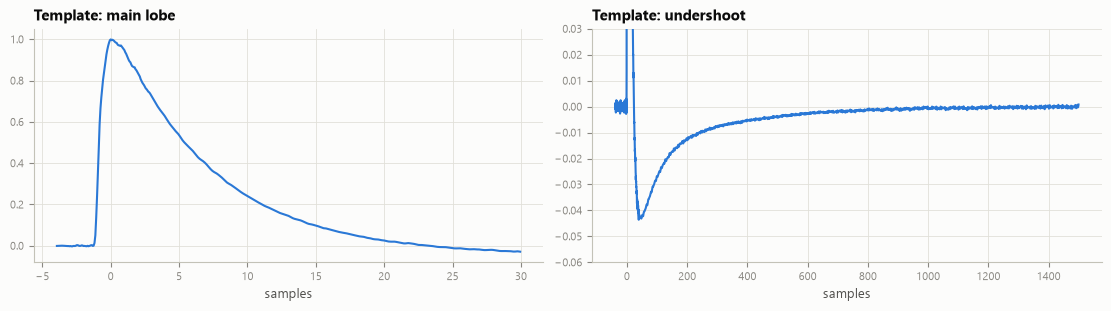

In [30]:
phi_before = np.mod(np.array([0.10, 0.15, 0.18, 0.5, 0.52, 0.9]), 1)
print("equalize_phase example: fitted phases", phi_before, "->", np.round(template.equalize_phase(phi_before), 3))
fig, ax = P.figure(1, 2, height_per_row=3.0)
ax[0,0].plot(Tb.t[(Tb.t>-4)&(Tb.t<30)], Tb.shape[(Tb.t>-4)&(Tb.t<30)]); ax[0,0].set_title("Template: main lobe"); ax[0,0].set_xlabel("samples")
ax[0,1].plot(Tb.t, Tb.shape); ax[0,1].set_ylim(-0.06, 0.03); ax[0,1].set_title("Template: undershoot"); ax[0,1].set_xlabel("samples")
plt.show()

## B9. `template.fit_multiexp(template)` with `multiexp_model` and `_exp_gauss`

The analytic model is a sum of exponentials starting at $t_0$, smoothed by a Gaussian of
width σ (the electronics bandwidth):

$$s(t) = \sum_k a_k\, \big[e^{-(t-t_0)/\tau_k} H(t-t_0)\big] * \mathcal N(0,\sigma),\qquad \sum_k a_k = 0$$

(the sum of amplitudes is 0, so the pulse starts from zero). Each smoothed exponential is
closed form (`_exp_gauss`). With $x = t - t_0$ and $z = (\sigma/\tau - x/\sigma)/\sqrt2$:

$$e^{-x/\tau} * \mathcal N = \tfrac12 e^{\sigma^2/2\tau^2 - x/\tau}\operatorname{erfc}(z)
= \tfrac12 e^{-x^2/2\sigma^2}\operatorname{erfcx}(z)$$

The second form is used for $z \ge 0$ to avoid overflow. `fit_multiexp` fits
$t_0, \sigma, \log\tau_k, a_k$ by nonlinear least squares (`scipy.optimize.least_squares`).

In [31]:
m3 = template.fit_multiexp(Tb)
m4 = template.fit_multiexp(Tb, taus0=tuple(m3.taus) + (5 * m3.taus[-1],), amps0=tuple(m3.amps[1:]) + (0.005,))
for name, m in [("3 exponentials", m3), ("4 exponentials", m4)]:
    print(f"{name}: taus = {np.round(m.taus, 2)} samples = {np.round(m.taus / 1.8, 3)} µs; amps = {np.round(m.amps, 4)}; sigma = {m.sigma:.3f}; rms = {m.rms:.2e}")

3 exponentials: taus = [  0.46   7.28 146.12] samples = [ 0.256  4.043 81.177] µs; amps = [-1.301   1.3581 -0.0571]; sigma = 0.062; rms = 1.43e-03
4 exponentials: taus = [  0.45   7.49  76.85 330.15] samples = [  0.249   4.162  42.696 183.415] µs; amps = [-1.286   1.358  -0.0558 -0.0163]; sigma = 0.066; rms = 7.16e-04


## B10. `noise.pulse_free_windows(x, free, 512)` and `noise.noise_spectrum(windows, fs)`

* `pulse_free_windows` finds runs of the free mask (edges of `diff(mask)`) and cuts
  non-overlapping 512-sample windows from runs that are long enough.
* `noise_spectrum`: subtract each window's mean, apply a Hann window $w$, FFT, average:
  $$\text{PSD}(f) = \frac{2\,\overline{|X(f)|^2}}{f_s\sum w^2}\quad[\mathrm{V^2/Hz}]$$
  (×2 for a one-sided spectrum). The autocorrelation is the inverse FFT of the zero-padded
  power spectrum, divided by (n − lag) (unbiased) and normalised to 1 at lag 0.

In [32]:
wnd, starts = noise.pulse_free_windows(x1, free, 512)
ns = noise.noise_spectrum(wnd, FS)
print("input:", wnd.shape, "windows;  output: sigma", round(ns.sigma_v * 1e3, 3), "mV, white floor", f"{ns.white_level:.2e}", "V²/Hz")
top = np.argsort(ns.psd)[::-1][:5]
print("strongest PSD bins (kHz):", np.round(np.sort(ns.freq_hz[top]) / 1e3, 1))
print("autocorrelation lags 0-4:", np.round(ns.autocorr[:5], 3))

input: (13, 512) windows;  output: sigma 1.257 mV, white floor 1.93e-13 V²/Hz
strongest PSD bins (kHz): [376.2 379.7 622.3 843.8 847.3]
autocorrelation lags 0-4: [ 1.    -0.094  0.044  0.015  0.448]


## B11. `characterize.characterize(store, out_dir)` (the step-2 driver)

Calls `scan` (B1–B6 for every capture), `build_template` (B8), `fit_multiexp` (B9),
`shape_by_amplitude` (templates per amplitude bin with the same alignment, compared to a
reference stacked from all pulses), `noise_spectrum` (B10, split into quiet and noisy
captures), a template fit of all pulses with a clean main lobe (preliminary spectrum), and
writes `template.h5`, `noise.h5`, `summary.json` and the plots. The results are in
`docs/characterization.md`.

---
# Part C: Pre-processing (step 3)

The chain is `preprocess.Preprocessor.process(volts)`:
polarity + offset → **line removal** (C1–C3) → **pole-zero** (C4–C6) → **baseline tracker** (C7).

## C0. Polarity and offset
`x = to_positive(volts)`, then subtract the **mean**. The coupled pulses have zero net
area, so the mean of the signal equals the electronic offset (a median would be biased by
the undershoots).

In [33]:
xs = signal.to_positive(volts1); off = xs.mean(); xs = xs - off
print("offset (mean):", off, " vs median:", np.median(signal.to_positive(volts1)))

offset (mean): 0.0006864489899407291  vs median: -0.001186803758


## C1. `interference.detect_lines(x, free, fs, cfg)`

1. Zero out the pulses (mask from a coarse trigger, 20 before / 60 after each), apply a Hann
   window, take the FFT of the **whole capture** (resolution 3.4 Hz), power P(f).
2. Local floor: running median over 1001 bins. A line is a bin with P > 100 × floor that is
   the largest within ±3.5 kHz (2 × fs/block).
3. Refine each frequency with a parabola through log P at the three bins around the peak.
4. Merge lines closer than 3.5 kHz (keep the strongest). At most 40.

In [34]:
sg = signal.noise_sigma(xs)
fr_mask = signal.pulse_free_mask(xs.size, signal.find_pulses(xs, sg, 5), 20, 60)
cfgL = interference.LineRemovalConfig()
lines = interference.detect_lines(xs, fr_mask, FS, cfgL)
print("output:", lines.size, "lines (kHz):", np.round(lines / 1e3, 2))
print("multiples of 9 kHz (= fs/200)?", np.round(lines / 9e3, 2))

output: 22 lines (kHz): [378.   440.99 468.01 495.   504.   540.01 558.   576.   621.   639.   666.   693.   729.   774.   780.75
 800.52 810.   819.   846.   863.99 870.54 891.  ]
multiples of 9 kHz (= fs/200)? [42.   49.   52.   55.   56.   60.   62.   64.   69.   71.   74.   77.   81.   86.   86.75 88.95 90.   91.
 94.   96.   96.73 99.  ]


## C2. `interference.subtract_lines(x, free, freqs, fs, cfg)`

In blocks of L = 1024 samples with 50 % overlap, model the interference as
$\sum_k \alpha_k\cos(2\pi f_k t) + \beta_k\sin(2\pi f_k t)$ (t = time within the block).
This is linear: $y \approx X c$ with a fixed design matrix X (L × 2K). The fit must use only
pulse-free samples. Instead of solving a different masked problem per block, fill the masked
samples with the current model and refit with the same X (an EM iteration):

$$c \leftarrow (X^TX)^{-1}X^T \tilde y,\qquad \tilde y = m\,y + (1-m)\,Xc$$

All blocks are solved at once ($\tilde Y\,[(X^TX)^{-1}X^T]^T$). Three passes converge.
The blocks are overlap-added with $\sin^2$ windows (they sum to 1), and the model is
subtracted from **every** sample. Inside a pulse the interference is interpolated, so the
pulse itself is untouched.

noise sigma before: 1.422 mV  after: 0.41 mV


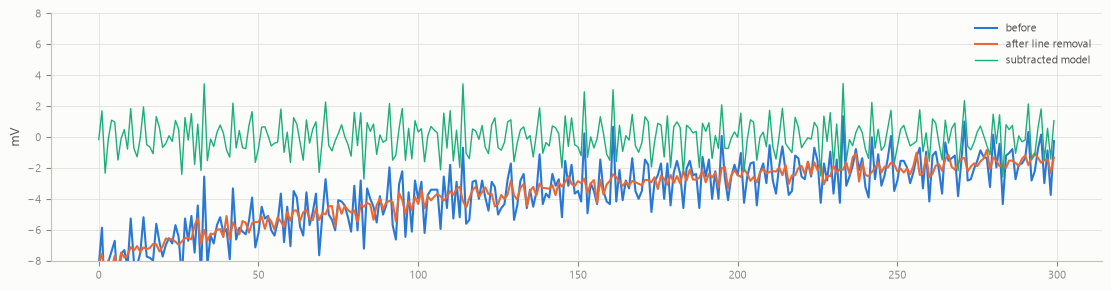

In [35]:
model = interference.subtract_lines(xs, fr_mask, lines, FS, cfgL)
xl = xs - model
print("noise sigma before:", round(signal.noise_sigma(xs) * 1e3, 3), "mV  after:", round(signal.noise_sigma(xl) * 1e3, 3), "mV")
seg = slice(200000, 200300)
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(xs[seg] * 1e3, label="before"); ax[0,0].plot(xl[seg] * 1e3, label="after line removal"); ax[0,0].plot(model[seg] * 1e3, label="subtracted model", linewidth=1)
ax[0,0].set_ylim(-8, 8); ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## C3. `interference.LineRemoval.process(x, free)`
C1 then C2 for one capture; `info` holds the lines and the rms removed.

## C4. `baseline.design_pole_zero(taus, amps)` (from `design_from_template`)

The sampled pulse model is $s[n] = \sum_i a_i\, p_i^{\,n}$ with $p_i = e^{-1/\tau_i}$. Its
z-transform is

$$S(z) = \sum_i \frac{a_i}{1-p_i z^{-1}} = \frac{N(z)}{\prod_i (1-p_i z^{-1})},\qquad
N(z) = \sum_i a_i \prod_{j\ne i}(1-p_j z^{-1})$$

The AC coupling appears twice: as slow **poles** $p_i$ (τ > 30 samples: the undershoot)
and as **zeros of N near z = 1** (they make the net area zero). The correction filter swaps
them:

$$G(z) = \frac{\prod_{\text{slow}}(1-p_i z^{-1})}{\prod_{\text{near 1}}(1-r_k z^{-1})}$$

so $G\cdot S$ has no undershoot. A root at or above 1 would be unstable and is clamped to
$1 - 1/20000$ (a slow leak).

In [36]:
pz = baseline.design_from_template(T)
taus, amps = np.asarray(T.meta["model_taus"]), np.asarray(T.meta["model_amps"])
p = np.exp(-1 / taus)
N = np.zeros(len(p))
for i in range(len(p)):
    q = np.array([1.0])
    for j in range(len(p)):
        if j != i: q = np.convolve(q, [1, -p[j]])
    N = N + amps[i] * q
print("model taus (samples):", np.round(taus, 2), " poles p_i:", np.round(p, 5))
print("roots of N(z):", np.round(np.roots(N), 6))
print("output:", pz.describe())
print("   b =", pz.b, "\n   a =", pz.a)

model taus (samples): [  0.44   7.51  75.94 317.67]  poles p_i: [0.10387 0.87537 0.98692 0.99686]
roots of N(z): [7.40375e+15 1.00018e+00 9.91032e-01]
output: P/Z: cancels tau = [75.9, 317.7] samples, replacement poles tau = [19999.5, 111.0] samples
   b = [ 1.      -1.98377  0.98382] 
   a = [ 1.      -1.99098  0.99098]


## C5. `baseline.PoleZero.process(x)`
Runs the IIR filter $y = G\,x$ (`scipy.signal.lfilter`) and keeps its internal state `zi`
between calls, so a capture processed in chunks gives exactly the same result as in one
piece (streaming-ready). It starts "at rest" on the first sample's level.

chunked == whole: True


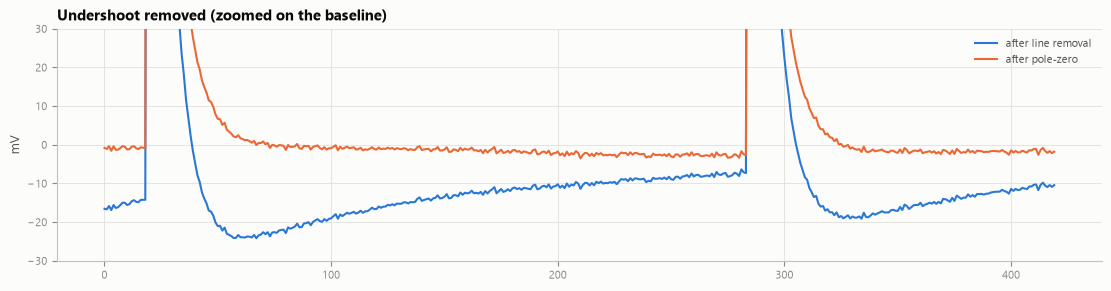

In [37]:
pzs = baseline.PoleZero(pz)
xp = pzs.process(xl)
pz2 = baseline.PoleZero(pz)
chunks = np.concatenate([pz2.process(c) for c in np.array_split(xl, 7)])
print("chunked == whole:", np.allclose(chunks, xp))
p1 = int(pk[30]); seg = slice(p1 - 20, p1 + 400)
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(xl[seg] * 1e3, label="after line removal"); ax[0,0].plot(xp[seg] * 1e3, label="after pole-zero")
ax[0,0].set_ylim(-30, 30); ax[0,0].set_ylabel("mV"); ax[0,0].set_title("Undershoot removed (zoomed on the baseline)"); ax[0,0].legend(); plt.show()

## C6. `baseline.filter_template(template, b, a)`
The detector and the fit must use the pulse shape **as it looks after** pole-zero. The
fine-grid template is evaluated on each of the 16 sub-sample phases, each phase sequence
is filtered at the sample rate, and the results are interleaved back and renormalised.

In [38]:
Tp = baseline.filter_template(T, pz.b, pz.a)
tt = np.array([0., 10, 30, 46, 100, 300])
print("t (samples)        :", tt)
print("template           :", np.round(T(tt), 4))
print("pole-zero template :", np.round(Tp(tt), 4))

t (samples)        : [  0.  10.  30.  46. 100. 300.]
template           : [ 0.9994  0.2376 -0.0287 -0.0431 -0.0273 -0.008 ]
pole-zero template : [ 1.000e+00  2.825e-01  2.180e-02  9.000e-04 -1.000e-03 -8.000e-04]


## C7. `baseline.track_baseline(x, free, cfg)` (inside `BaselineTracker.process`)
A centred moving average of the pulse-free samples (1001 samples; pulses masked 10 before
and 50 after). With cumulative sums of $x\cdot m$ and of $m$:

$$\hat b[i] = \frac{\sum_{j=i-500}^{i+500} x_j m_j}{\sum_{j=i-500}^{i+500} m_j}$$

computed in O(1) per sample. Windows with fewer than 50 free samples are bridged by
interpolation. The estimate is subtracted. Pole-zero boosts slow drift (×13 at 90 Hz), and
this removes it, so the two always go together (ADR-0005).

In [39]:
sp = signal.noise_sigma(xp)
fm = signal.pulse_free_mask(xp.size, signal.find_pulses(xp, sp, 5), 10, 50)
b_est = baseline.track_baseline(xp, fm, baseline.TrackerConfig())
xc = xp - b_est
w = 1500  # warm-up: pole-zero starts without knowing the tails of pulses before the capture
print(f"baseline estimate in the warm-up region (first {w} samples): {b_est[:w].min()*1e3:.1f} to {b_est[:w].max()*1e3:.1f} mV")
print("baseline estimate at samples 1500, 10k, 30k, 100k, 300k (mV):", np.round(b_est[[1500, 10000, 30000, 100000, 300000]] * 1e3, 2))
print("-> pole-zero restores a slowly wandering DC level of a few mV (its low-frequency gain);")
print("   the tracker (1001-sample window) follows it, so the corrected signal stays at zero")
print("median of pulse-free samples before:", round(np.median(xp[w:][fm[w:]]) * 1e3, 3), "mV  after:", round(np.median(xc[w:][fm[w:]]) * 1e3, 3), "mV")

baseline estimate in the warm-up region (first 1500 samples): -3.5 to -3.1 mV
baseline estimate at samples 1500, 10k, 30k, 100k, 300k (mV): [-3.37 -1.52 -1.7  -5.43 -4.98]
-> pole-zero restores a slowly wandering DC level of a few mV (its low-frequency gain);
   the tracker (1001-sample window) follows it, so the corrected signal stays at zero
median of pulse-free samples before: -3.001 mV  after: -0.016 mV


## C8. `preprocess.Preprocessor.process(volts)` (the whole chain)
C0 → C1–C3 → C5 → C7 in one call, with every stage switchable in `PreprocessConfig`.

In [40]:
pre = preprocess.Preprocessor(FS, preprocess.PreprocessConfig(), pz)
y1 = pre.process(volts1)
print("info:", {k: (np.round(v, 5) if np.ndim(v) == 0 else f"{len(v)} lines") for k, v in vars(pre.info).items()})
print("identical to the step-by-step result:", np.allclose(y1, xc))

info: {'offset_v': np.float64(0.00069), 'sigma_in_v': np.float64(0.00142), 'sigma_out_v': np.float64(0.00041), 'line_freqs_hz': '22 lines', 'line_rms_v': np.float64(0.00109)}
identical to the step-by-step result: True


---
# Part D: Detection and events (step 4)

## D1. `detect.kernel_from_template(T, pre=6, post=60)`
The pole-zero template sampled at integer offsets −6…60: the pulse shape **s** used by all filters.

In [41]:
det = detect.Detector(Tp)
print("s =", np.round(det.s, 3), " length", det.s.size)

s = [ 0.     0.     0.     0.002 ... -0.002 -0.002 -0.002 -0.002]  length 67


## D2. `detect.noise_autocovariance(x, free, n_lags)`
The noise covariance from pulse-free samples only (gapped estimator), with $m$ the mask:

$$r[k] = \frac{\sum_i x_i m_i\, x_{i+k} m_{i+k}}{\sum_i m_i m_{i+k}}$$

Both sums are autocorrelations, computed with FFTs (zero-padded to avoid wrap-around) on
the central 131,072 samples.

In [42]:
coarse = signal.find_pulses(y1, signal.noise_sigma(y1), 5)
freeD = signal.pulse_free_mask(y1.size, coarse, 20, 120)
r = detect.noise_autocovariance(y1, freeD, det.s.size)
print("r[0..5] (V²):", r[:6], "   -> correlation", np.round(r[:6] / r[0], 3))

r[0..5] (V²): [3.97344e-07 2.51174e-07 2.57884e-07 2.76586e-07 2.66203e-07 2.42668e-07]    -> correlation [1.    0.632 0.649 0.696 0.67  0.611]


## D3. `detect.optimal_kernel(s, r)`

The best linear amplitude estimator in coloured noise (generalised least squares) is
$\hat A = h^T x / h^T s$ with

$$h = C^{-1}s,\qquad C_{ij} = r[|i-j|]$$

C is Toeplitz, so `scipy.linalg.solve_toeplitz` (Levinson recursion, O(L²)) solves it
directly. Its noise is $\sigma_{\hat A} = (s^T C^{-1} s)^{-1/2}$, the smallest possible.

In [43]:
from scipy.linalg import toeplitz
h = detect.optimal_kernel(det.s, r)
C = toeplitz(r)
s_ = det.s
print("h (normalised) =", np.round(h / np.abs(h).max(), 2))
# noise of A = h.x / h.s is sqrt(h' C h) / (h.s): optimal -> (s' C^-1 s)^-1/2; matched (h = s) -> sqrt(s' C s) / (s.s)
print("theoretical output noise: optimal", round(1e3 / np.sqrt(s_ @ h), 3), "mV;  plain matched",
      round(1e3 * np.sqrt(s_ @ C @ s_) / (s_ @ s_), 3), "mV")

h (normalised) = [-0.28 -0.34 -0.51 -0.63 ... -0.03 -0.06 -0.05 -0.07]
theoretical output noise: optimal 0.256 mV;  plain matched 0.902 mV


## D4. `detect.apply_filter(x, h, s, pre)`

$$y[n] = \frac{\sum_k h[k]\, x[n+k-\text{pre}]}{\sum_k h[k]\, s[k]}$$

If x contains A·s with its peak at n₀, then y[n₀] = A exactly, for **any** kernel h. That
is why the matched filter (h = s) and the optimal filter (h = C⁻¹s) are on the same scale.
Implemented as an FFT correlation.

In [44]:
yo = detect.apply_filter(y1, h, det.s, 6)
ym = detect.apply_filter(y1, det.s, det.s, 6)
q = int(pk[30])
print(f"pulse at {q}: peak sample {y1[q]*1e3:.2f} mV; optimal filter {yo[q]*1e3:.2f} mV; matched filter {ym[q]*1e3:.2f} mV")

pulse at 13788: peak sample 351.15 mV; optimal filter 341.10 mV; matched filter 348.87 mV


## D5. `detect.negative_side_sigma(y)` and `detect.local_sigma(y, 4096)`

Pulses make y positive, so the noise is measured from its negative half: for zero-mean
Gaussian noise $\operatorname{median}(|y|\,:\,y<0) = 0.6745\,\sigma$. `local_sigma` does
this in blocks of 4096 samples and interpolates between block centres, so the threshold
follows interference bursts.

In [45]:
print("negative_side_sigma: optimal", detect.negative_side_sigma(yo) * 1e3, "mV;  matched", detect.negative_side_sigma(ym) * 1e3, "mV")
ls = detect.local_sigma(yo, 4096)
print("local sigma p10/p50/p90 (mV):", np.round(np.percentile(ls, [10, 50, 90]) * 1e3, 3))

negative_side_sigma: optimal 0.37961203000449556 mV;  matched 0.7100033677016406 mV
local sigma p10/p50/p90 (mV): [0.328 0.377 0.473]


## D6. `Detector.response_table(h)`
The filter output produced by a unit pulse whose peak lies p/16 of a sample after a sample
(p = 0…15), over ±66 samples: 16 rows × 133 columns. It is computed directly as one matrix
product of sliding windows with h. Cancellation (D7) subtracts these exact responses.

In [46]:
R = det.response_table(h)
print("shape:", R.shape, "  peak of phase 0:", R[0].max().round(4))
span = R.shape[1] // 2
print("response before the peak (phase 0, offsets -30…-2):", np.round(R[0, span-30:span-1], 3))

shape: (16, 133)   peak of phase 0: 1.0
response before the peak (phase 0, offsets -30…-2): [-0.083 -0.093 -0.085 -0.068 ... -0.081  0.043  0.238  0.518]


## D7. `detect.successive_cancellation(y, R, thr, margin)`

The optimal filter's response has negative dips and small bumps (above), which a plain
peak search would report as extra pulses. Successive cancellation (CLEAN):

1. Take candidates (local maxima above the threshold) in **descending** order (`_cancel_pass`).
2. For each: re-check it in the **residual** output (it may have shrunk when a neighbour
   was subtracted). Accept only if residual ≥ threshold + 3 % × (largest accepted pulse
   whose response overlaps here), it is a local maximum, and it is **not within ±2 samples
   of an accepted pulse** (there, only template mismatch of the real pulse remains).
3. Parabola through the three samples → sub-sample position → phase row p of R.
   $A = y_r[j] / R_p[j-\text{base}]$; subtract $A\,R_p$ from the residual.
4. **Search the residual again** (up to 4 passes): a small pulse hidden under a larger
   pulse's negative dip is not a local maximum of the original output, but it appears once
   the larger pulse has been subtracted.
5. Return the accepted positions, amplitudes and the residual.

Below: a real close pile-up from this capture.

close pair at 8507 8515 (gap 8 samples), amplitudes [ 62.5 265.2] mV


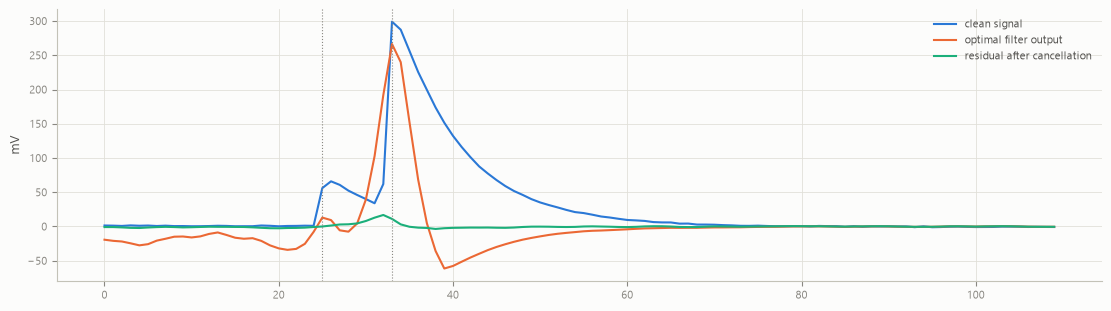

In [47]:
thr, sigma_y = det._threshold(yo)
idxc, ampc, resid = detect.successive_cancellation(yo, R, thr, det.cfg.margin)
gaps = np.diff(idxc); k = int(np.flatnonzero((gaps >= 4) & (gaps <= 12))[0])
a0 = idxc[k] - 25
seg = slice(a0, a0 + 110)
print("close pair at", idxc[k], idxc[k + 1], "(gap", gaps[k], "samples), amplitudes", np.round(ampc[k:k+2] * 1e3, 1), "mV")
fig, ax = P.figure(1, 1, height_per_row=3.0)
t_ = np.arange(110)
ax[0,0].plot(t_, y1[seg] * 1e3, label="clean signal"); ax[0,0].plot(t_, yo[seg] * 1e3, label="optimal filter output")
ax[0,0].plot(t_, resid[seg] * 1e3, label="residual after cancellation")
for j in (k, k + 1): ax[0,0].axvline(idxc[j] - a0, color=P.MUTED, linewidth=0.8, linestyle=":")
ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## D8. `Detector.detect(x)` (two passes)
filter (D2–D4) → threshold from the output (D5) → cancellation (D7) → **re-estimate the
noise from the residual** (real pulses' dips had inflated it) → cancellation again with the
lower threshold.

In [48]:
d1 = det.detect(y1)
print(f"output: {d1.index.size} pulses; filter noise {d1.sigma*1e3:.3f} mV (first pass {sigma_y*1e3:.3f}); median threshold {d1.threshold_v*1e3:.2f} mV")
print("first indices:", d1.index[:8], " amplitudes (mV):", np.round(d1.filter_amplitude[:8] * 1e3, 1))

output: 1314 pulses; filter noise 0.271 mV (first pass 0.380); median threshold 1.49 mV
first indices: [ 454  966 1398 2102 2155 2292 2633 3700]  amplitudes (mV): [252.4 152.5  82.  319.  161.5 179.2 225.7 251.4]


## D9. Alternatives: `detect.sharpen(x, tau)` and `decay_constant(T)`
`decay_constant` fits log s(t) over 4…25 samples (τ ≈ 7.7). `sharpen` computes
$x[n] - a\,x[n-1]$ with $a=e^{-1/\tau}$: an exponential decay becomes 0, so each pulse
collapses onto its rising edge (method `"sharpened"`).

In [49]:
print("decay constant:", detect.decay_constant(Tp))
print("sharpened template around the peak:", np.round(detect.sharpen(Tp(np.arange(-3, 8.)), detect.decay_constant(Tp)), 3))

decay constant: 7.687663946178681
sharpened template around the peak: [ 0.002 -0.001  0.385  0.662  0.061  0.01  -0.001 -0.003 -0.004 -0.003 -0.003]


## D10. `pipeline.Pipeline.process_capture(volts, capture, t0)`

For one capture: pre-process (C8) → detect (D8) → then

* **gaps** to the neighbours; **clusters**: a new cluster starts when the gap ≥ 60 samples
  (a template fit window is −10…+40, so closer pulses share one);
* **flags**: PILEUP (cluster > 1), WARMUP (first 1500 samples), EDGE, then the template fit
  (B7, baseline fixed at 0) of isolated pulses → amplitude, shift, rms; BAD_FIT if
  rms > 4σ + 2 % × A; LARGE (> 1.5 V) and AFTER_LARGE (200 samples after one);
* **snippets**: clean waveform of each pile-up cluster (−20…+80 samples), kept for re-analysis;
* **pile-up solver** (`_solve_clusters`, explained in E9–E10): amplitudes and sub-sample
  times for every pulse in a cluster (and for badly fitted isolated pulses), plus pulses
  found by its residual search (flag FIT_ADDED); gaps and cluster sizes recomputed;
* **time** = capture time + (index + shift) × Δt.

In [50]:
pipe = pipeline.Pipeline(T, FS)
with store.CaptureStore(SRC_STORE) as s:
    ev, row, sn = pipe.process_capture(s.volts(1), 1, float(s.time_s[1]))
names = ["index", "amplitude", "filter_amplitude", "shift", "fit_rms", "flags", "cluster", "cluster_size", "gap_prev"]
print(" ".join(f"{n:>16s}" for n in names))
for e in ev[5:15]:
    print(" ".join(f"{e[n]:16.5g}" for n in names))
print("\ncapture row:", row[0])
print("snippets:", len(sn), "; first:", sn[0][0], "capture", sn[0][1], "start", sn[0][2], "length", sn[0][3].size)

           index        amplitude filter_amplitude            shift          fit_rms            flags          cluster     cluster_size         gap_prev
            2292          0.18417          0.17915          0.55535        0.0011918                0                4                1              137
            2633          0.22558          0.22566        -0.029068       0.00085698                0                5                1              341
            3700          0.24955          0.25139        -0.092292       0.00068217                0                6                1             1067
            4810           0.0878         0.086172          0.63046       0.00042949                0                7                1             1110
            5063          0.36592          0.37061         -0.32934          0.00108                0                8                1              253
            5409         0.096401         0.095608          0.58116       0.000717

## D11. `pipeline.run(...)`, `events.EventWriter`, `events.EventFile`, `summarize`

`run` processes all captures (in parallel worker processes, `_worker_run`), makes cluster
ids unique, and appends each capture's rows with `EventWriter.append` to resizable,
compressed column datasets. `EventFile` reads everything back (`events`, `captures`,
`snippet(cluster)`, `clean()`, `live_time_s`). `summarize` reports rates and flags.

In [51]:
r = pipeline.run(SRC_STORE, TEMPLATE, TMP / "ev.h5", limit=5, workers=1, verbose=False)
print("run:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()})
ef = events.EventFile(TMP / "ev.h5")
print("events:", ef.events.size, " live time:", round(ef.live_time_s, 3), "s  clean:", ef.clean().size, " snippets:", ef.n_snippets)
cap, start, w = ef.snippet(int(ef.events[(ef.events["flags"] & events.FLAG_PILEUP) != 0]["cluster"][0]))
print("a snippet:", cap, start, w.shape)
print(json.dumps(pipeline.summarize(TMP / "ev.h5"), indent=1)[:600])

run: {'captures': 5, 'events': 6619, 'elapsed_s': 3.83, 'samples_per_s': 684583.97, 'file_bytes': 692254, 'text_bytes': 36700160}
events: 6619  live time: 1.452 s  clean: 4828  snippets: 768
a snippet: 0 508 (179,)
{
 "events": 6619,
 "live_time_s": 1.4520749999999998,
 "rate_cps": 4544.5311020436275,
 "clean": 4828,
 "snippets": 768,
 "flag_fractions_of_valid": {
  "pileup": 0.2620093953629338,
  "warmup": 0.0,
  "edge": 0.0,
  "bad_fit": 0.02621609334747689,
  "large": 0.0015153811183512653,
  "after_large": 0.002273071677526898,
  "fit_added": 0.0033338384603727837
 },
 "median_filter_sigma_mv": 0.2772504687309265,
 "median_threshold_mv": 1.529123067855835
}


## D12. `spectrum.fit_peaks(values, centers, lo, hi, bin_width)`
Histogram, then fit N Gaussians on a linear background by weighted least squares
(`curve_fit`, Poisson weights $1/\sqrt{\max(n,1)}$). Resolution = FWHM / centre with
FWHM = 2√(2 ln 2) σ = 2.355 σ. Here: the ⁶⁰Co lines from the full 100-capture event file.

centres (V): [0.3157 0.3573]  FWHM: [6.47 5.86] %  ± [0.08 0.07]
ratio of centres: 1.1317 (1332/1173 = 1.1355)


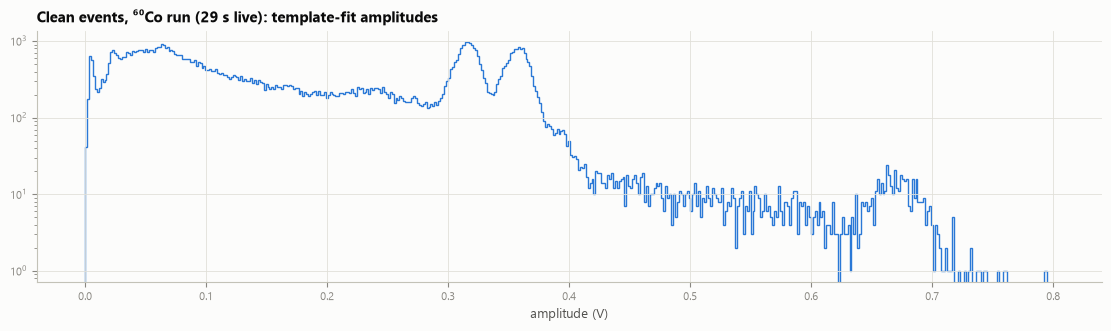

In [52]:
efull = events.EventFile(ROOT / "data/events/source_first100.h5")
amp = efull.clean()["amplitude"]
pf = spectrum.fit_peaks(amp, [0.316, 0.357], 0.27, 0.40, 0.002)
print("centres (V):", np.round(pf.centers, 4), " FWHM:", np.round(100 * pf.resolution, 2), "%  ±", np.round(100 * pf.resolution_err, 2))
print("ratio of centres:", round(pf.centers[1] / pf.centers[0], 4), "(1332/1173 = 1.1355)")
edges = np.linspace(0, 0.8, 500)
fig, ax = P.figure(1, 1, height_per_row=3.2)
ax[0,0].stairs(np.histogram(amp, edges)[0], edges); ax[0,0].set_yscale("log"); ax[0,0].set_xlabel("amplitude (V)")
ax[0,0].set_title("Clean events, ⁶⁰Co run (29 s live): template-fit amplitudes"); plt.show()

---
# Part E: Pile-up resolution (step 5)

A pile-up cluster is a stretch of clean signal with two or more pulses closer than 60
samples. Every method in `gamma_spectrometry.pileup` takes the cluster waveform **y** (baseline 0),
the detected peak positions **pos** (relative to the start of y) and a `PileupContext`, and
returns one amplitude per pulse. We use a real ⁶⁰Co pile-up cluster from the event file.

## E0. A real cluster: `EventFile.snippet(cluster)`

cluster 1305: capture 1, snippet starts at sample 75753, length 108
positions in the snippet: [20. 28.]  detector amplitudes (mV): [314.3  21.5]


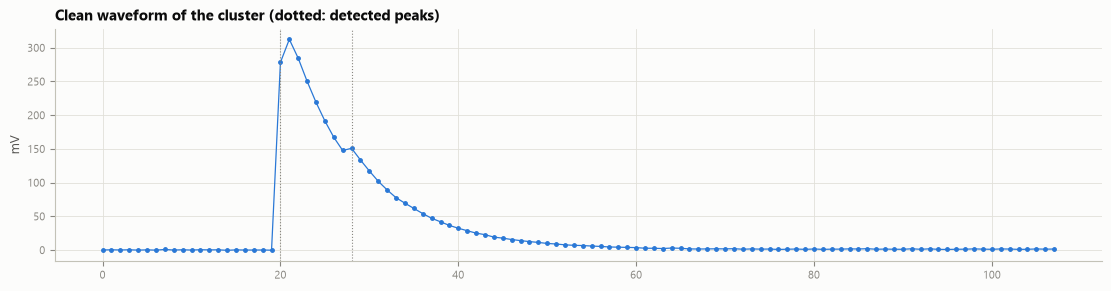

In [53]:
ev_all = efull.events
ok_flags = (ev_all["flags"] & (events.FLAG_WARMUP | events.FLAG_EDGE)) == 0
cand = ev_all[(ev_all["cluster_size"] == 2) & (ev_all["gap_next"] >= 6) & (ev_all["gap_next"] <= 10)
              & (ev_all["filter_amplitude"] > 0.25) & ok_flags]
cl = int(cand["cluster"][0])
cap, start, yc = efull.snippet(cl)
rows = ev_all[ev_all["cluster"] == cl]
pos = (rows["index"] - start).astype(float)
print(f"cluster {cl}: capture {cap}, snippet starts at sample {start}, length {yc.size}")
print("positions in the snippet:", pos, " detector amplitudes (mV):", np.round(rows["filter_amplitude"] * 1e3, 1))
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(yc * 1e3, marker="o", markersize=2.5, linewidth=0.9)
for p_ in pos: ax[0,0].axvline(p_, color=P.MUTED, linestyle=":", linewidth=0.8)
ax[0,0].set_ylabel("mV"); ax[0,0].set_title("Clean waveform of the cluster (dotted: detected peaks)"); plt.show()

## E1. `pileup.PileupContext`
Holds what the methods need: the (pole-zero-corrected) template **s**, its decay constant
τ (for HYPER), the noise autocovariance (for GLS/WLS), the template mismatch ε (for WLS),
and the timing-refinement settings. `derivative(t)` is the central difference
$s'(t) \approx [s(t+h) - s(t-h)]/2h$ with h = 1/16 sample. The noise autocovariance here is
measured from capture 1's pulse-free samples (as in D2), now with 4096 lags.

In [54]:
from gamma_spectrometry import pileup
r_long = detect.noise_autocovariance(y1, freeD, 4096)
ctx = pileup.PileupContext(Tp, detect.decay_constant(Tp), r_long)
print("tau =", round(ctx.tau, 3), " model_error eps =", ctx.model_error, " noise variance r[0] =", r_long[0])
print("s(t) and s'(t) at t = -1, 0, 1, 5:", np.round(Tp(np.array([-1., 0, 1, 5])), 3), np.round(ctx.derivative(np.array([-1., 0, 1, 5])), 3))

tau = 7.688  model_error eps = 0.0035  noise variance r[0] = 3.9734448329256136e-07
s(t) and s'(t) at t = -1, 0, 1, 5: [0.385 1.    0.939 0.558] [ 1.692 -0.003 -0.113 -0.096]


## E2. `pileup.tm(y, pos, ctx)`: template matching (the paper)

Measured amplitude of pulse p = the sample at its peak, $b_p = y[t_p]$. Each $b_p$ is the
pulse's own amplitude plus the tails of the **earlier** pulses at that point:

$$b_p = \sum_{q \le p} M_{pq}\, a_q,\qquad M_{pq} = s(t_p - t_q),\quad M_{pp} = s(0) = 1$$

M is lower triangular with a unit diagonal, so a is found by forward substitution
(`solve_triangular`). It uses **one sample per pulse**, and assumes the peak is exactly on
a sample.

In [55]:
b_meas = yc[np.round(pos).astype(int)]
dd = pos[:, None] - pos[None, :]
M = np.where(dd >= 0, Tp(dd), 0.0)
print("b =", np.round(b_meas * 1e3, 2), "mV\nM =\n", np.round(M, 4))
print("a = M^-1 b =", np.round(pileup.tm(yc, pos, ctx) * 1e3, 2), "mV")

b = [278.35 150.87] mV
M =
 [[1.     0.    ]
 [0.3705 1.    ]]
a = M^-1 b = [278.35  47.73] mV


## E3. `pileup.hyper(y, pos, ctx)`: HYPER

For mono-exponential pulses $A_q e^{-\lambda(t-t_q)}$, between pulse p and p+1:

$$D(t) = y(t) + \lambda\int_{t_p}^{t} y\,dt' = \sum_{q\le p} A_q e^{-\lambda(t_p - t_q)} = \text{const} = D_p$$

(differentiate: $\dot y = -\lambda y$ between pulses, so $\dot D = 0$). Hence
$D_p = A_p + D_{p-1}e^{-\lambda(t_p - t_{p-1})}$ and

$$A_p = D_p - D_{p-1}\,e^{-\lambda (t_p - t_{p-1})}$$

D_p is averaged over the segment (trapezoidal integral, from the peak, at most 3τ long).
Our pulses are not purely exponential (finite rise), which biases HYPER.

In [56]:
lam = 1 / ctx.tau
p_ = np.round(pos).astype(int)
for k in range(p_.size):
    a_, b_ = p_[k], min(p_[k + 1] if k + 1 < p_.size else yc.size, p_[k] + int(3 * ctx.tau))
    seg_ = yc[a_:b_]; integ = np.concatenate([[0.0], np.cumsum(0.5 * (seg_[1:] + seg_[:-1]))])
    Dt = seg_ + lam * integ
    print(f"segment {k}: D(t) first values {np.round(Dt[:6] * 1e3, 1)} mV -> mean D_{k} = {Dt.mean() * 1e3:.2f} mV")
print("HYPER amplitudes:", np.round(pileup.hyper(yc, pos, ctx) * 1e3, 2), "mV")

segment 0: D(t) first values [278.4 350.9 361.7 362.3 361.7 360.7] mV -> mean D_0 = 349.54 mV
segment 1: D(t) first values [150.9 152.1 152.1 151.1 150.7 150. ] mV -> mean D_1 = 152.40 mV
HYPER amplitudes: [349.54  28.93] mV


## E4. `pileup.ls(y, pos, ctx)`: least squares with integer times

Model the **whole** cluster: $y(t) = \sum_k A_k\, s(t - t_k) + \text{noise}$. With the
design matrix $S_{tk} = s(t - t_k)$ (one column per pulse) this is linear:

$$\hat A = \arg\min \lVert y - S A\rVert^2 = (S^TS)^{-1}S^Ty$$

(`np.linalg.lstsq`). It uses all samples, so it averages noise, but it still assumes the
peaks are on samples.

In [57]:
t_ = np.arange(yc.size, dtype=float)
S = Tp(t_[:, None] - pos[None, :])
print("design matrix S:", S.shape, "  S^T S =\n", np.round(S.T @ S, 3))
print("LS amplitudes:", np.round(pileup.ls(yc, pos, ctx) * 1e3, 2), "mV")

design matrix S: (108, 2)   S^T S =
 [[4.992 1.854]
 [1.854 4.992]]
LS amplitudes: [312.96  35.  ] mV


## E5. `pileup.ls_refine`: least squares with sub-sample timing (`_ls(refine=True)`)

The arrival times are refined jointly with the amplitudes (Gauss–Newton). For a small
time shift δ:

$$A\,s(t - t_k - \delta) \approx A\,s(t - t_k) - (A\delta)\, s'(t - t_k)$$

which is still linear, now in $A_k$ and $(A\delta)_k$: solve
$y \approx [\,S \;\; -S'\,]\,[A;\; A\delta]$, take $\delta_k = (A\delta)_k / A_k$
(at most ±0.5 per step, ±0.75 in total), update $t_k$, repeat 4 times, then solve for A at
the final times. Below, one step by hand, then the function.

In [58]:
Dmat = ctx.derivative(t_[:, None] - pos[None, :])
coef, *_ = np.linalg.lstsq(np.hstack([S, -Dmat]), yc, rcond=None)
A1, Ad1 = coef[:2], coef[2:]
print("one Gauss-Newton step: A =", np.round(A1 * 1e3, 2), "mV, delta =", np.round(Ad1 / A1, 3), "samples")
A_ref, t_ref = pileup._ls(yc, pos, ctx, refine=True, whiten=False)
print("ls_refine: A =", np.round(A_ref * 1e3, 2), "mV at times", np.round(t_ref, 3), "(detected:", pos, ")")

one Gauss-Newton step: A = [316.65  29.84] mV, delta = [0.233 0.059] samples
ls_refine: A = [322.23  24.33] mV at times [20.525 28.178] (detected: [20. 28.] )


## E6. `pileup.gls_refine`: whitened least squares (`_whitener`)

With noise covariance C (Toeplitz from the autocovariance), the maximum-likelihood estimate
minimises $(y - SA)^T C^{-1} (y - SA)$. With the Cholesky factor $C = LL^T$, multiply
everything by $L^{-1}$ (`solve_triangular`): the noise becomes white and ordinary least
squares applies to $L^{-1}y$ and $L^{-1}S$ ("prewhitening"). The timing refinement is the
same as E5.

In [59]:
from scipy.linalg import solve_triangular
Lc = pileup._whitener(ctx, yc.size)
print("Cholesky factor:", Lc.shape, " L[0:3,0:3] =\n", np.round(Lc[:3, :3] * 1e3, 4), "(mV)")
# whitening real noise: take pulse-free stretches of capture 1 as long as the cluster
wins_, _ = noise.pulse_free_windows(y1, freeD, yc.size)
z = np.array([solve_triangular(Lc, w_, lower=True) for w_ in wins_])
print(f"{len(wins_)} real noise windows: before whitening std {wins_.std()*1e3:.3f} mV, lag-1 correlation {np.corrcoef(wins_[:, :-1].ravel(), wins_[:, 1:].ravel())[0,1]:.3f}")
print(f"after L^-1: std {z.std():.3f} (should be 1), lag-1 correlation {np.corrcoef(z[:, :-1].ravel(), z[:, 1:].ravel())[0,1]:.3f} (should be 0)")
print("gls_refine: A =", np.round(pileup.gls_refine(yc, pos, ctx) * 1e3, 2), "mV")

Cholesky factor: (108, 108)  L[0:3,0:3] =
 [[0.6304 0.     0.    ]
 [0.3985 0.4884 0.    ]
 [0.4091 0.1805 0.4443]] (mV)
3042 real noise windows: before whitening std 0.646 mV, lag-1 correlation 0.639
after L^-1: std 1.013 (should be 1), lag-1 correlation -0.017 (should be 0)
gls_refine: A = [321.88  23.23] mV


## E7. `pileup.wls_refine`: noise + template-mismatch weighting (the chosen method)

GLS assumes the template is exact. Real pulses differ from it by a small, amplitude-
proportional amount. The fit residuals of the isolated pulses show it:

$$\text{rms}^2 = \sigma_0^2 + (\varepsilon A)^2$$

`wls_refine` adds that model error to the covariance:
$C = C_\text{noise} + (\varepsilon\, A_\max)^2 I$, with $A_\max$ from a first unweighted fit.
Small pulses (noise-dominated) are weighted like GLS; large pulses (mismatch-dominated) like
ordinary LS. Below, ε is measured from the clean events of the event file.

In [60]:
cl_ev = efull.clean(); a_ = cl_ev["amplitude"]; r_ = cl_ev["fit_rms"]
m_ = (a_ > 0.005) & (a_ < 0.6)
c0, c1 = np.linalg.lstsq(np.vstack([np.ones(m_.sum()), a_[m_] ** 2]).T, r_[m_] ** 2, rcond=None)[0]
print(f"fit of rms^2 = sigma0^2 + (eps A)^2 over {m_.sum()} clean events: sigma0 = {np.sqrt(c0)*1e3:.3f} mV, eps = {np.sqrt(c1)*100:.3f} %")
A0 = pileup.ls(yc, pos, ctx)
print(f"extra variance for this cluster: (eps * A_max)^2 = ({ctx.model_error} * {A0.max()*1e3:.1f} mV)^2 = {(ctx.model_error*A0.max()*1e3)**2:.3f} mV^2  vs noise r[0] = {r_long[0]*1e6:.3f} mV^2")
print("wls_refine: A =", np.round(pileup.wls_refine(yc, pos, ctx) * 1e3, 2), "mV")

fit of rms^2 = sigma0^2 + (eps A)^2 over 95267 clean events: sigma0 = 0.673 mV, eps = 0.351 %
extra variance for this cluster: (eps * A_max)^2 = (0.0035 * 313.0 mV)^2 = 1.200 mV^2  vs noise r[0] = 0.397 mV^2
wls_refine: A = [321.69  23.3 ] mV


## E8. `pileup.resolve(method, y, pos, ctx)`: all methods on this cluster
`resolve` dispatches by name. Below: every method's amplitudes, and the WLS fit with its
residual.

tm          [278.35  47.73] mV
hyper       [349.54  28.93] mV
ls          [312.96  35.  ] mV
ls_refine   [322.23  24.33] mV
gls_refine  [321.88  23.23] mV
wls_refine  [321.69  23.3 ] mV


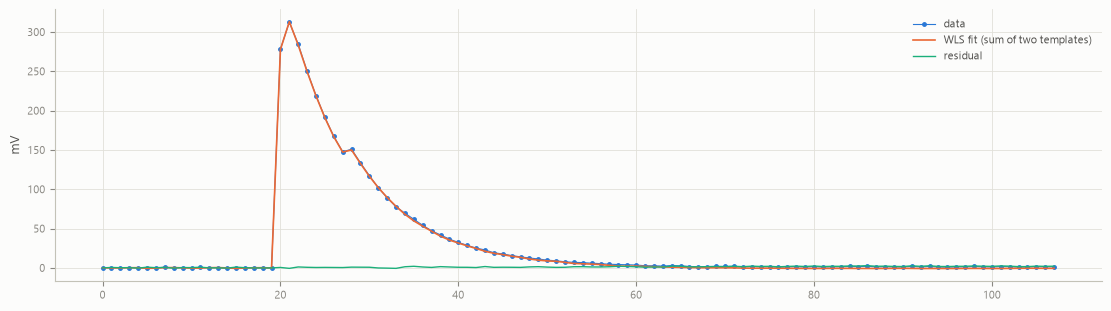

In [61]:
for m in pileup.METHODS:
    print(f"{m:11s}", np.round(pileup.resolve(m, yc, pos, ctx) * 1e3, 2), "mV")
A_w, t_w = pileup._ls(yc, pos, ctx, refine=True, whiten=True,
                      extra_var=(ctx.model_error * pileup.ls(yc, pos, ctx).max()) ** 2)
model_w = Tp(t_[:, None] - t_w[None, :]) @ A_w
fig, ax = P.figure(1, 1, height_per_row=3.0)
ax[0,0].plot(t_, yc * 1e3, marker="o", markersize=2.5, linewidth=0.8, label="data")
ax[0,0].plot(t_, model_w * 1e3, linewidth=1.2, label="WLS fit (sum of two templates)")
ax[0,0].plot(t_, (yc - model_w) * 1e3, linewidth=1.0, label="residual")
ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## E9. `solver.PileupSolver` (step 6): the chosen method inside the pipeline

`PileupSolver(template, noise_acov, SolverConfig)` is built once per capture.

* `taper_autocovariance(acov, 512)`: keeps 512 lags and tapers the last quarter smoothly
  to 0 (half-cosine). An abruptly truncated autocovariance can make the Toeplitz matrix
  indefinite, and then the Cholesky factorisation fails.
* `_whitener(n, extra_var)`: C = Toeplitz(r) + extra_var·I → Cholesky L → **W = L⁻¹**,
  formed once per cluster, so every later whitening is a single matrix product.
* `_fit(y, t0, W, Wy)`: the WLS + timing fit of E5–E7, solving the small normal equations
  $(X_w^T X_w)\,c = X_w^T y_w$ each iteration and stopping when no time moves by more
  than 0.005 samples (times stay within ±1.25 samples of the detected positions).
  `PulseTemplate.derivative(t)` gives s'(t) from a precomputed central-difference array,
  and `PulseTemplate.__call__` interpolates by direct indexing on its uniform grid.
* `solve(y, positions)`: (1) unweighted LS to get $A_\max$ for the mismatch term;
  (2) whitening matrix; (3) fit; (4) **residual search**: for candidate times τ every half
  sample, with whitened residual $r_w$ and whitened template $s_w(\tau)$,

  $$A^*(\tau) = \frac{s_w\cdot r_w}{s_w\cdot s_w},\qquad z(\tau) = \frac{s_w\cdot r_w}{\sqrt{s_w\cdot s_w}}$$

  ($z^2$ is the drop in $\chi^2$ from adding that pulse). If max z > 8, positive, at least
  one sample from the existing pulses: add it, refit everything, and keep it only if its
  amplitude is still > 8σ. (5) rms and whitened χ² per sample.

Below: a real cluster where the detector saw **one** pulse but the solver found two.

detected positions: [10] -> solver times: [10.09  8.3 ] amplitudes (mV): [320.9 137.4] added: [False  True]
rms 1.388 mV, whitened chi2 per sample 0.23
without the search: one pulse of 422.2 mV, rms 19.234 mV, chi2 121.3


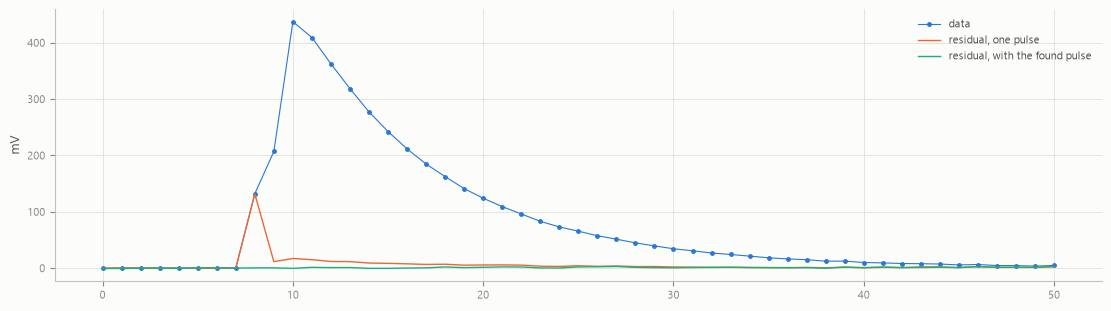

In [62]:
from gamma_spectrometry import solver
ev_s = efull.events
added_ev = ev_s[(ev_s["flags"] & events.FLAG_FIT_ADDED) != 0]
pick = added_ev[(added_ev["amplitude"] > 0.03)][0]
cap_s, cl_s = int(pick["capture"]), int(pick["cluster"])
rows_s = ev_s[ev_s["cluster"] == cl_s]
detected_rows = rows_s[(rows_s["flags"] & events.FLAG_FIT_ADDED) == 0]
pipe_s = pipeline.Pipeline(T, FS)
with store.CaptureStore(SRC_STORE) as s:
    pipe_s.pre.reset(); ys = pipe_s.pre.process(s.volts(cap_s))
a_s = int(detected_rows["index"][0]) - 10
b_s = int(detected_rows["index"][-1]) + 41
free_s = signal.pulse_free_mask(ys.size, pipe_s.detector.detect(ys).index, 20, 120)
sv = solver.PileupSolver(Tp, detect.noise_autocovariance(ys, free_s, 512), solver.SolverConfig())
res_s = sv.solve(ys[a_s:b_s], detected_rows["index"] - a_s)
print("detected positions:", detected_rows["index"] - a_s, "-> solver times:", np.round(res_s.time, 2),
      "amplitudes (mV):", np.round(res_s.amplitude * 1e3, 1), "added:", res_s.added)
print(f"rms {res_s.rms*1e3:.3f} mV, whitened chi2 per sample {res_s.chi2:.2f}")
no_search = solver.PileupSolver(Tp, detect.noise_autocovariance(ys, free_s, 512), solver.SolverConfig(residual_search=False))
r1 = no_search.solve(ys[a_s:b_s], detected_rows["index"] - a_s)
tt_s = np.arange(b_s - a_s, dtype=float)
m1 = Tp(tt_s[:, None] - r1.time[None, :]) @ r1.amplitude
m2 = Tp(tt_s[:, None] - res_s.time[None, :]) @ res_s.amplitude
print(f"without the search: one pulse of {r1.amplitude[0]*1e3:.1f} mV, rms {r1.rms*1e3:.3f} mV, chi2 {r1.chi2:.1f}")
fig, ax = P.figure(1, 1, height_per_row=3.0)
ax[0,0].plot(tt_s, ys[a_s:b_s] * 1e3, marker="o", markersize=2.5, linewidth=0.8, label="data")
ax[0,0].plot(tt_s, (ys[a_s:b_s] - m1) * 1e3, linewidth=1.0, label="residual, one pulse")
ax[0,0].plot(tt_s, (ys[a_s:b_s] - m2) * 1e3, linewidth=1.0, label="residual, with the found pulse")
ax[0,0].set_ylabel("mV"); ax[0,0].legend(); plt.show()

## E10. `Pipeline._solve_clusters`, `EventFile.good()` and `pipeline.spectrum_report`

* `_solve_clusters(e, y, detected)`: noise autocovariance of the capture (pulse-free mask
  around the detections); for each cluster of > 1 pulse, and each isolated pulse flagged
  BAD_FIT, `solve` the window [first − 10, last + 40]; write amplitudes, shifts
  (= solver time − index) and rms; set or clear BAD_FIT (rms > 4σ + 2 % A_max); append
  found pulses as new rows (PILEUP | FIT_ADDED); sort; recompute gaps and cluster sizes.
* `EventFile.good(include_pileup=True)`: every event with a finite amplitude whose flags are
  only PILEUP / FIT_ADDED (how it was measured), i.e. no warm-up, edge, bad fit or large
  pulse. `clean()` stays "no flags at all" (isolated pulses).
* `spectrum_report(events)`: Gaussian peak fits (`fit_peaks`, D12) of isolated, resolved
  pile-up (by gap) and all good events, with shifts relative to isolated and the
  throughput (good / valid events). Categories with < 1000 events in the peak region are
  not fitted.

In [63]:
rep = pipeline.spectrum_report(ROOT / "data/events/source_first100.h5")
print(f"throughput {100*rep['throughput']:.1f} % (isolated only {100*rep['isolated_fraction']:.1f} %), pulses found by the solver: {rep['fit_added']}")
for name, c in rep["categories"].items():
    if "error" in c:
        print(f"  {name:46s} n={c['n']:6d}  not fitted ({c['error']})")
    else:
        print(f"  {name:46s} n={c['n']:6d}  FWHM {' / '.join(f'{x:.2f}' for x in c['fwhm_pct'])} %   shift {' / '.join(f'{x:+.2f}' for x in c['shift_pct'])} %")

throughput 97.3 % (isolated only 73.0 %), pulses found by the solver: 595
  isolated                                       n= 96827  FWHM 6.47 / 5.84 %   shift +0.00 / +0.00 %
  pile-up (all)                                  n= 32143  FWHM 6.45 / 5.94 %   shift -0.05 / -0.08 %
  pile-up, gap < 3 (incl. found by the solver)   n=   523  not fitted (too few events in the peak region (116))
  pile-up, gap 3-10                              n=  5641  FWHM 7.54 / 5.61 %   shift +0.04 / -0.02 %
  pile-up, gap 10-30                             n= 11072  FWHM 6.22 / 6.33 %   shift +0.08 / -0.11 %
  pile-up, gap 30-60                             n= 14907  FWHM 6.34 / 5.75 %   shift -0.18 / -0.09 %
  all good events                                n=128970  FWHM 6.47 / 5.86 %   shift -0.01 / -0.02 %


---
# Part G: Energy calibration and background subtraction (step 7)

Input: the good events of the source run and of the background run (event files from
`gamma-spectrometry process`). Output: both on a keV axis, live-time-normalised spectra, and the
net spectrum.

## G1. `calibration.anchor_gain(amplitudes, kind)`
A first gain (keV per volt) from an unmistakable line. `_peaks_in` histograms the
amplitudes between their median and 99.5th percentile (400 bins), smooths them, and returns
the most prominent peaks. Starting at the median keeps a crowd of small (noise) triggers
from swamping the search (this matters for the naive chain of Part H).
* **source:** the pair of peaks whose centre ratio is closest to 1332.5 / 1173.2 = 1.1357
  (within 2 %) is ⁶⁰Co: gain = mean(1173.2 / A₁, 1332.5 / A₂);
* **background:** the strongest peak is ⁴⁰K: gain = 1460.8 / A.

In [64]:
from gamma_spectrometry import calibration, analysis
src_good = efull.good()
bkg_good = events.EventFile(ROOT / "data/events/background.h5").good()
g_src = calibration.anchor_gain(src_good["amplitude"], "source")
g_bkg = calibration.anchor_gain(bkg_good["amplitude"], "background")
print(f"source anchor gain {g_src:.1f} keV/V  ->  1173.2 keV predicted at {1173.228/g_src:.4f} V")
print(f"background anchor gain {g_bkg:.1f} keV/V ->  1460.8 keV predicted at {1460.82/g_bkg:.4f} V")

source anchor gain 3714.7 keV/V  ->  1173.2 keV predicted at 0.3158 V
background anchor gain 3974.8 keV/V ->  1460.8 keV predicted at 0.3675 V


## G2. `calibration.fit_lines(amplitudes, lines, gain)` → `_fit_group`

Each library line is predicted at A = E / gain. Lines within 16 % of each other form a
group and are fitted together by `spectrum.fit_peaks` with **bounds**: centre ±4 %, width
0.5–2× the expected NaI resolution
$\sigma(E) = E \cdot \tfrac{0.065}{2.3548}\sqrt{1173/E}$ (`expected_sigma_rel`), area ≥ 0.
A line is accepted if its area is ≥ 4σ, its centre and width are not at a bound, and its
FWHM is 2.5–15 %. If any are rejected, one is dropped and the rest of the group refitted,
until all remaining lines are accepted. Lines whose centre or width is at a bound are
dropped first (they are the degenerate ones), then the least significant.

In [65]:
pts = calibration.fit_lines(src_good["amplitude"], calibration.SOURCE_LINES, g_src)
for p_ in pts:
    print(f"{p_.label:10s} {p_.energy_kev:8.1f} keV  A = {p_.amplitude_v:.4f} V  FWHM {p_.fwhm_pct:5.2f} %  area {p_.area:7.0f}  "
          + ("accepted" if p_.accepted else "rejected: " + p_.note))

Co-60        1173.2 keV  A = 0.3156 V  FWHM  6.49 %  area   14855  accepted
Co-60        1332.5 keV  A = 0.3572 V  FWHM  5.87 %  area   13197  accepted
K-40         1460.8 keV  A = 0.3925 V  FWHM  2.92 %  area     252  rejected: width pinned at its bound (FWHM 2.9 %): not a measured peak
Co-60 sum    2505.7 keV  A = 0.6709 V  FWHM  5.62 %  area     451  accepted
Tl-208       2614.5 keV  A = 0.6902 V  FWHM  2.22 %  area      46  rejected: FWHM 2.2 % outside (2.5, 15.0)


## G3. `calibration.fit_calibration(points)`

Weighted least squares of $E = \sum_i c_i A^i$ through the accepted points. The weight of a
point is $1/\sigma_E$ with $\sigma_E^2 = (\sigma_A \cdot \text{gain})^2 + (0.001\,E)^2$ (centre
uncertainty plus a 0.1 % systematic). Linear by default; quadratic only with ≥ 4 points and
if it halves χ²/ndf. With exactly two points the line passes through them, and a weak pin
at (0, 0) keeps the offset reasonable.

In [66]:
cal_src = calibration.fit_calibration(pts)
print("coefficients (keV, keV/V):", np.round(cal_src.coeffs, 3), "  chi2/ndf", round(cal_src.chi2_ndf, 2))
for lab, e_, r_ in cal_src.residuals_kev():
    print(f"  residual {lab:10s} {e_:8.1f} keV: {r_:+.2f} keV")

coefficients (keV, keV/V): [ -10.818 3755.368]   chi2/ndf 3.44
  residual Co-60        1173.2 keV: +1.33 keV
  residual Co-60        1332.5 keV: -1.93 keV
  residual Co-60 sum    2505.7 keV: +2.79 keV


## G4. `calibration.gain_match(points, reference)`

The background run has only ⁴⁰K. Same detector and electronics, so the calibration
*shape* (offset, curvature) is taken from the source run, with one gain factor k:

$$E_{bkg}(A) = E_{ref}(k A) = \sum_i c_i k^i A^i$$

k is found for each accepted line by solving $E_{ref}(k A_\text{line}) = E_\text{line}$
(Brent's method), and averaged with weights $(A/\sigma_A)^2$.

In [67]:
pts_b = calibration.fit_lines(bkg_good["amplitude"], calibration.BACKGROUND_LINES, g_bkg)
print("accepted background lines:", [(p_.label, p_.energy_kev) for p_ in pts_b if p_.accepted])
cal_bkg = calibration.gain_match(pts_b, cal_src)
k_ = cal_bkg.coeffs[1] / cal_src.coeffs[1]
print(f"k = {k_:.4f}: the background run's gain is {100*(1-1/k_):.1f} % lower;  E_bkg(A) = {cal_bkg.coeffs[0]:.2f} + {cal_bkg.coeffs[1]:.2f} A")
print(f"without gain matching, the background 40K would appear at {cal_src.energy(pts_b[[p_.label for p_ in pts_b].index('K-40')].amplitude_v):.0f} keV")

accepted background lines: [('K-40', 1460.82), ('Tl-208', 2614.511)]
k = 1.0760: the background run's gain is 7.1 % lower;  E_bkg(A) = -10.82 + 4040.83 A
without gain matching, the background 40K would appear at 1358 keV


## G5. `calibration.calibrate(...)` and `calibration.gain_vs_time(events, kind)`
`calibrate` = anchor (G1) → lines (G2) → curve (G3), or gain matching (G4) when only one
line is usable; repeated once with the gain from the accepted lines. `gain_vs_time` refits
the anchor line(s) in chunks of 20 captures; relative gain per chunk (± its uncertainty).

In [68]:
print("source:", np.round(calibration.calibrate(src_good["amplitude"], "source").coeffs, 3))
for g_ in calibration.gain_vs_time(src_good, "source"):
    print(f"  captures {g_['first_capture']:3d}-{g_['first_capture']+19:3d}: gain {g_['relative_pct']:+.2f} % ± {g_['relative_err_pct']:.2f} %")

source: [ -12.935 3761.619]
  captures   0- 19: gain +0.12 % ± 0.05 %
  captures  20- 39: gain -0.08 % ± 0.05 %
  captures  40- 59: gain -0.01 % ± 0.04 %
  captures  60- 79: gain -0.03 % ± 0.05 %
  captures  80- 99: gain +0.01 % ± 0.05 %


## G6. `analysis.energy_spectrum(...)` and `analysis.subtract(S, B)`

Each run's events → keV with its own calibration → histogram on common 5 keV bins →
divide by that run's live time. Per bin, with counts N and live times t:

$$r_\text{net} = \frac{N_s}{t_s} - \frac{N_b}{t_b},\qquad
\sigma^2 = \frac{N_s}{t_s^2} + \frac{N_b}{t_b^2}$$

(Poisson; empty bins count as 1 for the error).

In [69]:
edges_ = np.arange(0, 3000.1, 5.0)
S_ = analysis.energy_spectrum(cal_src.energy(src_good["amplitude"]), efull.live_time_s, edges_)
B_ = analysis.energy_spectrum(cal_bkg.energy(bkg_good["amplitude"]), events.EventFile(ROOT / "data/events/background.h5").live_time_s, edges_)
N_ = analysis.subtract(S_, B_)
i0 = np.searchsorted(edges_, 1450)
print("bin (keV)    source counts  bkg counts   source cps  bkg cps   net cps ± err")
for i in range(i0, i0 + 4):
    print(f"{edges_[i]:5.0f}-{edges_[i+1]:5.0f}   {S_.counts[i]:8.0f}     {B_.counts[i]:6.0f}     {S_.rate[i]:7.2f}   {B_.rate[i]:6.2f}   {N_.rate[i]:+6.2f} ± {N_.rate_err[i]:.2f}")

bin (keV)    source counts  bkg counts   source cps  bkg cps   net cps ± err
 1450- 1455         76         49        2.62     1.69    +0.93 ± 0.38
 1455- 1460         82         38        2.82     1.31    +1.52 ± 0.38
 1460- 1465         71         41        2.44     1.41    +1.03 ± 0.36
 1465- 1470         68         60        2.34     2.07    +0.28 ± 0.39


## G7. `analysis.fit_line_groups(spectrum)` → `fit_net_peaks`

Line rates from Gaussian fits on a linear continuum, in **local windows**
(`NET_GROUPS`): the ⁶⁰Co pair over 1040–1440 keV; ⁴⁰K over 1300–1650 keV with the 1332 keV
peak as a **nuisance** (area ≥ 0: it can be absent, not negative), because ⁴⁰K sits on its
flank. Reported lines may be negative (a line that should vanish in the net spectrum).

In [70]:
for name_, sp_ in (("source", analysis.NetSpectrum(edges_, S_.rate, S_.rate_err)),
                   ("background", analysis.NetSpectrum(edges_, B_.rate, B_.rate_err)), ("net", N_)):
    print(name_.ljust(10), "  ".join(f"{r_['label']} {r_['energy_kev']:.0f}: {r_['rate_cps']:7.2f} ± {r_['rate_err_cps']:.2f}" for r_ in analysis.fit_line_groups(sp_)))

source     Co-60 1173:  513.85 ± 6.23  Co-60 1332:  464.76 ± 6.54  K-40 1461:   29.43 ± 4.92
background Co-60 1173:   -7.29 ± 4.90  Co-60 1332:  -20.74 ± 10.95  K-40 1461:   40.42 ± 7.00
net        Co-60 1173:  521.41 ± 6.50  Co-60 1332:  488.63 ± 7.35  K-40 1461:    8.32 ± 3.06


## G8. `analysis.analyze(source, out_dir, background)` (the step-7 driver)
Calibrate both runs, build and subtract the spectra, fit the lines, measure the gain drift,
and write `calibration_*.json`, `spectrum.csv`, `spectrum_summary.json` and the plots. CLI:
`gamma-spectrometry spectrum SOURCE_EVENTS OUT_DIR --background BACKGROUND_EVENTS`. Results:
`docs/spectrum.md`.

totals above 120 keV (counts/s): {'source': 3943, 'background': 596, 'net': 3347}


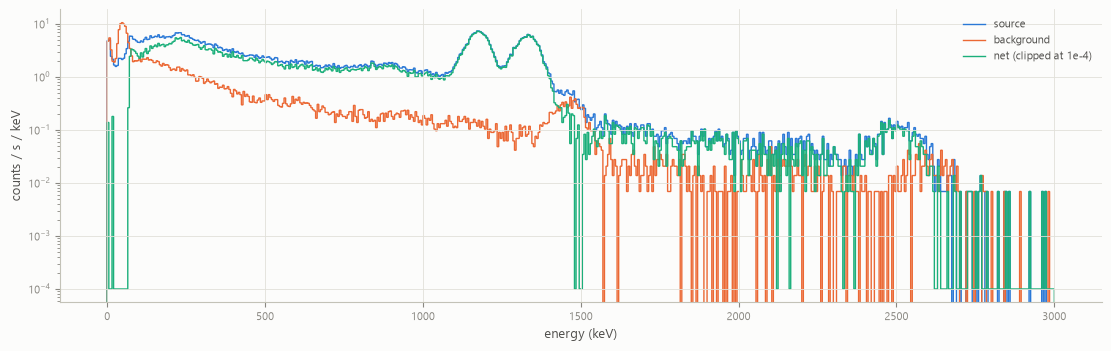

In [71]:
summ = analysis.analyze(ROOT / "data/events/source_first100.h5", TMP / "spec", ROOT / "data/events/background.h5", verbose=False)
print("totals above 120 keV (counts/s):", {k: round(v) for k, v in summ["totals_cps"].items()})
fig, ax = P.figure(1, 1, height_per_row=3.4)
w_ = np.diff(edges_)
ax[0,0].stairs(S_.rate / w_, edges_, label="source"); ax[0,0].stairs(B_.rate / w_, edges_, label="background")
ax[0,0].stairs(np.clip(N_.rate / w_, 1e-4, None), edges_, label="net (clipped at 1e-4)")
ax[0,0].set_yscale("log"); ax[0,0].set_xlabel("energy (keV)"); ax[0,0].set_ylabel("counts / s / keV"); ax[0,0].legend(); plt.show()

---
# Part H: Benchmark (naive count vs analog chain vs Gamma Spectrometry App)

The same captures through three chains; each is calibrated by `calibration.calibrate`
(Part G) and measured with the same metrics. Results on 100 captures: `docs/benchmark.md`.
Here, 5 captures to keep it quick.

## H1. `benchmark.naive_chain(store, captures, k=5, distance=5)`
No transformation: flip polarity, subtract the median, then `scipy.signal.find_peaks` with
height > k·σ (`signal.noise_sigma`) and ≥ `distance` samples between peaks. The pulse
height is the highest sample. Pulses on an undershoot are measured low, noise maxima count
as pulses, and pile-up merges or splits pulses.

In [72]:
from gamma_spectrometry import benchmark
caps5 = range(5)
naive = benchmark.naive_chain(SRC_STORE, caps5)
print(f"{naive.n_recorded} 'pulses' in {naive.live_time_s:.2f} s = {naive.n_recorded/naive.live_time_s:.0f} /s;  smallest heights (mV):", np.round(np.sort(naive.amplitudes)[:5]*1e3, 2))

8856 'pulses' in 1.46 s = 6081 /s;  smallest heights (mV): [7.12 7.12 7.12 7.12 7.12]


## H2. `benchmark.shaping_amplifier(x, dt, tau_shaping, tau_pz, n_integrators=4)`
The digital version of the analog shaping amplifier, CR-RC⁴ with pole-zero cancellation.
With $a = e^{-\Delta t/\tau}$ for each time constant:

$$H(z) = \underbrace{\frac{1 - a_{pz} z^{-1}}{1 - a_s z^{-1}}}_{\text{PZ-cancelled CR}}\;
\left(\frac{1 - a_s}{1 - a_s z^{-1}}\right)^{4}$$

The CR zero at $a_{pz}$ cancels the pulse's own 4.1 µs decay pole, so the input becomes a
clean $\tau_s$ exponential. Four RC integrators then make it a semi-Gaussian
$\propto t^4 e^{-t/\tau_s}$. In continuous time this peaks at $4\tau_s$; each zero-delay
digital stage runs ~½ sample ahead, so the sampled peak comes ≈ 2.5 samples earlier.

tau 0.5 us: peak 1 samples after the step, gain 0.333, end value 2.1e-23
tau 1 us: peak 5 samples after the step, gain 0.259, end value 1.2e-21
tau 2 us: peak 12 samples after the step, gain 0.225, end value 1.6e-09


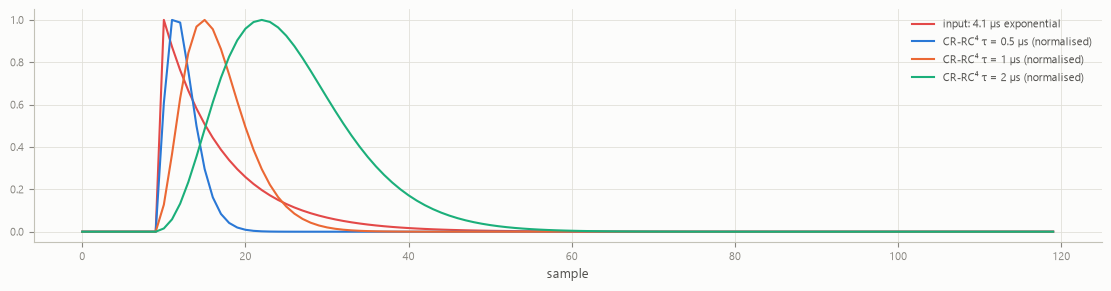

In [73]:
k_ = np.arange(120); xp = np.where(k_ >= 10, np.exp(-(k_ - 10) / FS / 4.1e-6), 0.0)
fig, ax = P.figure(1, 1, height_per_row=2.8)
ax[0,0].plot(k_, xp, color=P.SERIES[7], label="input: 4.1 µs exponential")
for i_, ts in enumerate([0.5e-6, 1e-6, 2e-6]):
    y_ = benchmark.shaping_amplifier(xp, 1 / FS, ts)
    ax[0,0].plot(k_, y_ / y_.max(), color=P.SERIES[i_], label=f"CR-RC⁴ τ = {ts*1e6:g} µs (normalised)")
    print(f"tau {ts*1e6:g} us: peak {np.argmax(y_) - 10} samples after the step, gain {y_.max():.3f}, end value {y_[-1]:.1e}")
ax[0,0].set_xlabel("sample"); ax[0,0].legend(); plt.show()

## H3. `benchmark.analog_chain(store, captures, tau_shaping, tau_pz, lld_sigma=5, dead_time=5e-6, pur=True)`
Per capture:
1. **shape** (H2);
2. **discriminate**: peaks of the shaped signal above 5σ, with σ from the negative side
   (`detect.negative_side_sigma`; differences between samples would underestimate the noise
   of a smooth signal);
3. **baseline restorer**: subtract `track_baseline` of the pulse-free samples;
4. **peak-hold ADC**: parabolic interpolation through the three samples around each maximum,
   $A = y_0 - \tfrac14 (y_- - y_+)\,\delta$ with $\delta = \tfrac{y_- - y_+}{2(y_- - 2y_0 + y_+)}$;
5. **pile-up rejector**: drop both pulses if two triggers are < 10 τ apart;
6. **dead time**: no conversion for 5 µs after each accepted one (non-extending).

The live-time clock stops during conversions and for rejected pile-up.

In [74]:
ana = benchmark.analog_chain(SRC_STORE, caps5, tau_shaping=1e-6, pur=True)
print(f"triggers {ana.n_triggers}, recorded {ana.n_recorded} ({100*ana.n_recorded/ana.n_triggers:.1f} %), live {ana.live_time_s:.3f} of {ana.real_time_s:.3f} s ({100*ana.live_time_s/ana.real_time_s:.1f} %)")

triggers 5818, recorded 5652 (97.1 %), live 1.423 of 1.452 s (98.0 %)


## H4. `benchmark.pipeline_chain(events, captures)` and `benchmark.metrics(chain)`
`pipeline_chain` takes the good events of the event file. `metrics` calibrates a chain and
returns, among others:
* the FWHM of 1173/1332 keV (joint bounded Gaussian fit, 1040–1440 keV, 2 keV bins);
* the valley-to-peak ratio (minimum between the peaks / mean peak maximum);
* the peak rates per live second (`analysis.fit_line_groups`);
* the pile-up continuum (1450–2450 keV);
* the low-energy threshold (1st percentile of recorded energies below 300 keV).

`run_benchmark` does this for all five chains and writes the summary and plot (CLI
`gamma-spectrometry benchmark`).

In [75]:
pipe = benchmark.pipeline_chain(ROOT / "data/events/source_first100.h5", caps5)
for ch in (naive, ana, pipe):
    m_ = benchmark.metrics(ch)
    print(f"{m_['name']:42s} FWHM {m_['fwhm_pct'][0]:.2f}/{m_['fwhm_pct'][1]:.2f} %  valley/peak {m_['valley_to_peak']:.3f}  threshold {m_['low_energy_threshold_kev']:.0f} keV")
print("(5 captures only: widths and valleys fluctuate by up to ~1 % here; docs/benchmark.md uses 100)")

naive find_peaks                           FWHM 7.30/7.69 %  valley/peak 0.238  threshold 19 keV


analog CR-RC4 1 us, with pile-up rejection FWHM 7.70/6.43 %  valley/peak 0.182  threshold 62 keV
Gamma Spectrometry App                     FWHM 6.36/6.13 %  valley/peak 0.110  threshold 11 keV
(5 captures only: widths and valleys fluctuate by up to ~1 % here; docs/benchmark.md uses 100)


---
# Part I: Configuration and the runner (step 9)

Everything above was called from code. A **run file** does the same without code
(`docs/configuration.md`).

## I1. `config.from_dict(d)` / `config.load(path, overrides)`
A nested dict (from TOML or JSON) → the config dataclasses, recursively. Missing keys keep
their defaults. Each value is checked against its field's type annotation; unknown keys,
wrong types, invalid choices (`CHOICES`) and out-of-range numbers (`POSITIVE`, ≥ 0) are
collected and raised together as a `ConfigError`.

In [76]:
from gamma_spectrometry import config as C
cfg = C.from_dict({"input": {"kind": "store", "source": str(SRC_STORE)}, "pipeline": {"detect": {"threshold": 6}}})
print(type(cfg.pipeline.detect).__name__, "threshold =", cfg.pipeline.detect.threshold, "| method (default) =", cfg.pipeline.detect.method)
try:
    C.from_dict({"input": {"knd": "raw"}, "pipeline": {"detect": {"method": "fast", "threshold": -2}}})
except C.ConfigError as e:
    print(e)

DetectConfig threshold = 6.0 | method (default) = optimal
invalid configuration:
  input.knd: unknown setting (did you mean 'kind'?)
  pipeline.detect.method: 'fast' is not one of 'optimal', 'matched', 'sharpened', 'edge'
  pipeline.detect.threshold: must be > 0, got -2.0


## I2. `config.set_key(d, "a.b.c=value")` and `config.dumps(cfg)`
`set_key` applies one `--set` override; the value is parsed as TOML (`6` → int, `true` →
bool, `"x"` → str). `dumps` writes TOML, one table per dataclass. The comment of each field
comes from its comment in the source code (`_comments` reads the class source).

In [77]:
d = {}
for s_ in ["pipeline.preprocess.line_removal=false", "pipeline.detect.method=matched", "input.limit=2"]:
    C.set_key(d, s_)
print(d)
print("\n".join(C.dumps(C.from_dict(d)).splitlines()[38:48]))

{'pipeline': {'preprocess': {'line_removal': False}, 'detect': {'method': 'matched'}}, 'input': {'limit': 2}}
# limit = (not set)  # only the first N captures

[pipeline.preprocess]
polarity = -1  # -1: pulses are negative-going (flipped to positive); 1: positive
line_removal = false  # stage: remove narrow interference lines (sinusoids)
pole_zero = true  # stage: pole-zero correction (removes the undershoot); needs baseline_tracker
baseline_tracker = true  # stage: subtract the slow baseline (moving average of pulse-free samples)
trigger_threshold = 5.0  # for the pulse masks used by the stages
line_mask_pre = 20  # line fit: samples excluded before each pulse ...
line_mask_post = 60  # ... and after it


## I3. `config.check(cfg)`
Checks that need more than one setting: required inputs and existing paths are errors,
combinations of stages that work badly are warnings.

In [78]:
c_ = C.load(None, [f"input.source='{SRC_STORE.as_posix()}'", f"template.path='{TEMPLATE.as_posix()}'",
                   "pipeline.preprocess.baseline_tracker=false"])
for w_ in C.check(c_):
    print("warning:", w_)

## I4. `runner.run(cfg)`
Input → template → events → spectrum → benchmark, each when selected. Every output gets a
stamp (`<file>.stamp.json`: its inputs and settings). A rerun reuses an output whose stamp
is unchanged, so after changing one setting only the affected steps run.

In [79]:
from gamma_spectrometry import runner
sets_ = [f"output='{(TMP / 'run').as_posix()}'", f"input.source='{SRC_STORE.as_posix()}'", f"template.path='{TEMPLATE.as_posix()}'",
         "input.limit=2", "spectrum.enabled=false", "workers=1"]
r_ = runner.run(C.load(None, sets_), verbose=False)
print({k: v["seconds"] for k, v in r_["steps"].items()})
r_ = runner.run(C.load(None, sets_), verbose=True)                                   # unchanged: reused
r_ = runner.run(C.load(None, sets_ + ["pipeline.detect.threshold=7"]), verbose=False)  # only processing reruns
print("stored in the event file:", C.pipeline_from_event_file(r_["events"]["source"]).detect.threshold)

{'input_source': 0.0, 'template': 0.0, 'process_source': 1.5}
[process] source: reusing C:\Users\Ayub\AppData\Local\Temp\tmpesug9pzh\run\events\source.h5 (same inputs and settings)


done in 0 s; outputs in C:\Users\Ayub\AppData\Local\Temp\tmpesug9pzh\run


stored in the event file: 7.0


---
# Part J: Simulation and streaming (step 10)

## J1. `simulate.analytic_template()` and `simulate.Simulator(cfg).read(n)`
The simulator builds the pulse from the analytic model fitted to the 2021 template (Part B,
`MODEL_2021`), with its peak at t = 0. `read(n)` returns the next n samples. Each pulse is
built as follows:
* **Arrivals:** Poisson in time, at the source and background rates.
* **Energy:** for each gamma of the decay (⁶⁰Co: 1173 *and* 1332 keV, same decay), it deposits
  with probability `efficiency`. Then the photopeak with P/T(E) ∝ E^−0.6, the backscatter
  energy E/(1+2E/mc²), or a Klein–Nishina Compton electron
  $\frac{d\sigma}{dT} \propto 2 + \frac{s^2}{\varepsilon^2(1-s)^2} + \frac{s}{1-s}\left(s-\frac{2}{\varepsilon}\right)$,
  s = T/E, ε = E/mc².
* **Summing and smearing:** deposits of one decay add up (true-coincidence summing), and are
  smeared by FWHM/E = 8 % · √(662/E).
* **Waveform:** amplitude E / gain × pulse(t − t₀). The pulse comes from a table of 128
  sub-sample phases. Then noise, interference sinusoids, the offset, the negative polarity
  and ADC rounding.

Events are generated in fixed 65,536-sample blocks, so the waveform does not depend on how
it is read.

47 true pulses in 20000 samples; first three: [(np.float64(491.16), 429.5), (np.float64(1116.4), 1127.0), (np.float64(2129.85), 893.3)]
same signal however it is read: True


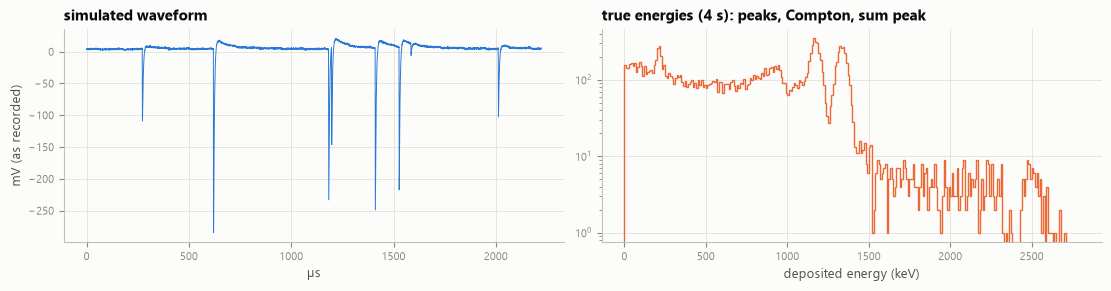

In [80]:
from gamma_spectrometry import simulate, sources, stream
sim = simulate.Simulator(simulate.SimConfig(seed=3))
x_sim = sim.read(20000)
T_ = sim.truth_table()
print(f"{T_.size} true pulses in {x_sim.size} samples; first three:", [(round(r['sample'], 2), round(float(r['energy_kev']), 1)) for r in T_[:3]])
a_, b_ = simulate.Simulator(simulate.SimConfig(seed=3)), simulate.Simulator(simulate.SimConfig(seed=3))
print("same signal however it is read:", np.array_equal(np.concatenate([a_.read(7), a_.read(19993)]), b_.read(20000)))
fig, ax = P.figure(1, 2, height_per_row=2.8)
ax[0,0].plot(np.arange(4000) / FS * 1e6, x_sim[:4000] * 1e3, color=P.SERIES[0], linewidth=0.7)
ax[0,0].set_xlabel("µs"); ax[0,0].set_ylabel("mV (as recorded)"); ax[0,0].set_title("simulated waveform")
long_ = simulate.Simulator(simulate.SimConfig(noise_v=0, seed=4)); long_.read(int(FS * 4)); E_ = long_.truth_table()["energy_kev"]
ax[0,1].hist(E_, np.arange(0, 2800, 10), histtype="step", color=P.SERIES[1]); ax[0,1].set_yscale("log")
ax[0,1].set_xlabel("deposited energy (keV)"); ax[0,1].set_title("true energies (4 s): peaks, Compton, sum peak"); plt.show()

## J2. `sources`: where samples come from
Every source yields `Chunk(data, new_segment, t0_s)`:
* `StoreSource` and `RawSource`: one segment per capture, read from a store or straight from
  the ASCII files;
* `SimulationSource`: one endless segment;
* `PipeSource`: binary samples from stdin, a file or a FIFO;
* `Paced(source)`: releases chunks at real time, which makes a source *live*.

In [81]:
for src_ in (sources.StoreSource(SRC_STORE, limit=1, chunk=200000), sources.SimulationSource(duration_s=0.2, chunk=200000)):
    cs_ = list(src_.chunks())
    print(f"{src_.description}: {len(cs_)} chunks of {[c.data.size for c in cs_]} samples, new_segment {[c.new_segment for c in cs_]}")

store D:\GammaSpectroscopy\data\source_first100.h5: 3 chunks of [200000, 200000, 124288] samples, new_segment [True, False, False]
simulation (co60, 3900 + 600 /s, seed 1): 2 chunks of [200000, 160000] samples, new_segment [True, False]


## J3. `stream.StreamProcessor`: overlapping frames
A segment is cut into frames:
* a core of `frame` samples;
* plus `pre` samples of context before it (more than the 1,500-sample warm-up) and `post`
  after it (fit windows, baseline tracker, clusters).

`process_frame` runs the unchanged `Pipeline.process_capture` on the whole frame and keeps
only the events whose peak is in the core. The frames are independent, so they run in
parallel workers. Samples travel to the workers as exact int32 ADC codes when they lie on the
ADC grid. A live source that gets ahead of the workers loses frames; they count as dead time
(no live time).

In [82]:
x_ = simulate.Simulator(simulate.SimConfig(seed=5)).read(300000)
res_ = {}
for frame_ in (300000, 65536):
    sp_ = stream.StreamProcessor(simulate.analytic_template(), FS, pipeline.PipelineConfig(),
                                 stream.StreamConfig(frame=frame_, update_s=0), workers=1)
    for a0 in range(0, x_.size, 40000):              # any chunking gives the same frames
        sp_.feed(x_[a0:a0 + 40000])
    st_ = sp_.close()
    res_[frame_] = np.concatenate([r[0] for r in sp_.results])
    print(f"frame {frame_}: {st_.frames} frames, {st_.events} events, live {st_.live_time_s:.4f} s")
e1, e2 = res_[300000], res_[65536]
j_ = np.clip(np.searchsorted(e2["time_s"], e1["time_s"]), 1, e2.size - 1)
same = np.minimum(abs(e2["time_s"][j_] - e1["time_s"]), abs(e2["time_s"][j_-1] - e1["time_s"])) * FS < 0.5
print(f"events of the single frame found again with 65536-sample frames: {100*same.mean():.2f} %")

frame 300000: 1 frames, 754 events, live 0.1658 s


frame 65536: 5 frames, 756 events, live 0.1658 s
events of the single frame found again with 65536-sample frames: 99.87 %


## J4. `stream.LiveSpectrum` and `stream.process_stream(source, template, out, ...)`
`process_stream` feeds a source to the processor and writes the event file. Every
`update_s` seconds it prints a status line, recalibrates the live spectrum (once it has
20,000 good events, and again at every doubling) and writes `live/<run>/live_spectrum.json`
(plus a PNG every `png_s`). A UI or `gamma-spectrometry stream --show` (`liveplot.LivePlot`) draws it.

In [83]:
simulate.analytic_template().save(TMP / "t_sim.h5")
r_ = stream.process_stream(sources.SimulationSource(simulate.SimConfig(seed=6), duration_s=2.0), TMP / "t_sim.h5",
                           TMP / "sim_events.h5", pipeline.PipelineConfig(), stream.StreamConfig(update_s=0), workers=1,
                           verbose=False, live_dir=TMP / "live")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r_.items() if k != "calibration"})
print("live spectrum calibration:", "not yet (fewer than 20,000 good events in 2 s)" if r_["calibration"] is None else np.round(r_["calibration"], 1))

{'frames': 14, 'dropped_frames': 0, 'samples': 3600000, 'stream_s': 2.0, 'events': 8713, 'live_time_s': 1.999, 'elapsed_s': 5.789, 'speed': 0.345}
live spectrum calibration: not yet (fewer than 20,000 good events in 2 s)


## J5. `simulate.compare_to_truth(events, truth)`
Detected events are matched to the true pulses by time (±2 samples), counting only the
truth inside each capture's live region (`live_start_s`, `live_time_s`). It reports:
* detection efficiency by true energy;
* false detections per second;
* amplitude bias and spread of good events above 50 mV;
* the fraction of close true pairs (2–60 samples) found as two events.

In [84]:
sim_t = sources.SimulationSource(simulate.SimConfig(seed=6), duration_s=2.0).sim; sim_t.read(int(2.0 * FS))
simulate.save_truth(TMP / "truth.h5", sim_t.truth_table(), sim_t.cfg)
c_ = simulate.compare_to_truth(TMP / "sim_events.h5", TMP / "truth.h5")
print({k: c_[k] for k in ("true_pulses", "detected", "false_rate_cps", "amplitude_bias_pct", "amplitude_spread_pct", "close_pairs_resolved")})
for e_ in c_["efficiency_by_energy"]:
    print(f"  {e_['energy_kev'][0]:4d}-{e_['energy_kev'][1]:4d} keV: {e_['true']:5d} true, found {100*e_['efficiency']:.1f} %")

{'true_pulses': 8831, 'detected': 8709, 'false_rate_cps': 12.505352985819766, 'amplitude_bias_pct': 0.5036414861679077, 'amplitude_spread_pct': 0.3067156672477722, 'close_pairs_resolved': 0.9930624380574826}
    30- 100 keV:   530 true, found 94.9 %
   100- 300 keV:  1479 true, found 99.4 %
   300- 600 keV:  1397 true, found 99.1 %
   600-1000 keV:  2065 true, found 99.9 %
  1000-1500 keV:  2894 true, found 99.8 %
  1500-3000 keV:   237 true, found 100.0 %


---
# Part K: The app (step 11)

`gamma-spectrometry app` opens a page in the browser (Streamlit, `gamma_spectrometry/app.py`). It is a front
end for the run file of Part I:
* **1 · Input:** where the signal comes from: raw files, a prepared store, a replay, the
  simulator, or a live file / FIFO;
* **2 · Processing:** the template, the stage switches (each with a one-line explanation),
  and the analysis steps;
* **All settings:** the complete run file as editable text, plus load and download;
* **3 · Run:** validation (`config.check`), **Run** and **Stop**, the log, and the live
  spectrum;
* **4 · Results:** steps, calibration, line rates, plots, the benchmark, and the truth check
  for simulations.

## K1. `app._w(widget, label, obj, attr, key)`: a widget bound to a setting
Each widget reads its start value from the configuration dataclass and writes the user's
choice back into it on every rerun of the page. So the page and the run file never
disagree. Editing the TOML text replaces the configuration and resets the widgets
(`_replace_cfg`).

## K2. `app.start_run(cfg)`, `progress_view()`, `stop_run()`
**Run** saves `<output>/ui_run.toml` and starts `python -m gamma_spectrometry run` on it as a separate
process. The page stays responsive, and **Stop** ends the process and its workers. Every
2 s, `progress_view` redraws the log and the live spectrum from
`live/<run>/live_spectrum.json`.

Below, the page is driven without a browser (Streamlit's `AppTest`): choose the simulator,
shorten the run, and look at the run file the page would start.

In [85]:
import logging; logging.getLogger("streamlit").setLevel(logging.ERROR)   # "bare mode" notices
from streamlit.testing.v1 import AppTest
at = AppTest.from_file(str(ROOT / "gamma_spectrometry" / "app.py"), default_timeout=60); at.run()
print("default page, errors shown:", [e.value.splitlines()[1].strip() for e in at.error])
at.radio(key="w.input.kind").set_value("simulation").run()
at.number_input(key="w.sim.dur").set_value(5.0).run()
at.checkbox(key="w.pp.line").set_value(False).run()
from gamma_spectrometry import config as C
txt = C.dumps(at.session_state["cfg"]).splitlines()
print("errors now:", [e.value for e in at.error], "| Run enabled:", not [b for b in at.button if b.label == "Run"][0].disabled)
print("\n".join(l for l in txt if l.startswith(("kind", "duration_s", "line_removal"))))

default page, errors shown: ['input.source: not set (a raw capture folder or an .h5 store)']
errors now: [] | Run enabled: True
kind = "simulation"  # "raw" | "store" (batch) | "replay" | "simulation" | "pipe" (streamed); see docs/configuration.md
line_removal = false  # stage: remove narrow interference lines (sinusoids)
duration_s = 5.0  # simulated source run (s of signal)


---
# Part F: Evaluation tools (not part of the pipeline)

These modules measure how well the pipeline works; they produced the numbers in the docs.

## F1. `restoration.default_configs()` and `restoration.evaluate(...)`
Every combination of pre-processing stages is applied to the **same** pulses (selected on
the raw signal). For each: noise, the baseline just before each pulse, the average tail
after isolated pulses, and Gaussian fits of the ⁶⁰Co peaks with free / fixed baseline, also
split into pulses on an earlier pulse's tail vs clean ones (`docs/baseline-restoration.md`).

In [86]:
from gamma_spectrometry import restoration
for name, cfg in restoration.default_configs().items():
    print(f"{name:30s} -> label: {cfg.label()}")

raw                            -> label: raw
lines                          -> label: line_removal
tracker only                   -> label: baseline_tracker
pole-zero                      -> label: pole_zero
lines + pole-zero              -> label: line_removal + pole_zero
lines + pole-zero + tracker    -> label: line_removal + pole_zero + baseline_tracker


## F2. `detection_eval.noise_streams`, `inject`, `_matched`, `_both_found`

* `noise_streams`: pulse-free stretches of the clean signal joined together (**real
  noise**), and the same with **randomised Fourier phases** (**pure noise**): identical
  power spectrum, but any pulse is smeared into noise, so detections in it are false.
* `inject`: adds template pulses at random sub-sample times (optionally a second one d
  samples later).
* `_matched` / `_both_found`: is a detection within ±2 samples of the truth? For pairs,
  two **distinct** detections are required.

In [87]:
from gamma_spectrometry import detection_eval
real_n, pure_n, _ = detection_eval.noise_streams(SRC_STORE, Tp, pz, [0, 50])
ns_r = noise.noise_spectrum(real_n[: real_n.size // 512 * 512].reshape(-1, 512), FS)
ns_p = noise.noise_spectrum(pure_n[: pure_n.size // 512 * 512].reshape(-1, 512), FS)
print(f"real noise {real_n.size} samples, rms {real_n.std()*1e3:.3f} mV; pure noise rms {pure_n.std()*1e3:.3f} mV")
print("PSD ratio pure/real at 50, 200, 500 kHz:", np.round(np.interp([5e4, 2e5, 5e5], ns_r.freq_hz, ns_p.psd / ns_r.psd), 2))
yi, ci, Ai = detection_eval.inject(real_n, Tp, [0.003], np.random.default_rng(0), second=(6, 0.03))
found_ = det.detect(yi).index
print("injected", ci.size, "pairs (3 mV then 30 mV, 6 samples apart): first found", detection_eval._matched(found_, np.round(ci).astype(int)).mean().round(3),
      "; both found as two events", detection_eval._both_found(found_, np.round(ci).astype(int), np.round(ci + 6).astype(int)).mean().round(3))

real noise 370944 samples, rms 0.722 mV; pure noise rms 0.722 mV
PSD ratio pure/real at 50, 200, 500 kHz: [1.06 1.   1.01]


injected 926 pairs (3 mV then 30 mV, 6 samples apart): first found 0.982 ; both found as two events 0.982


## F3. `pileup_eval`: the three pile-up tests

* `make_context(template, noise)`: template → pole-zero design → filtered template, decay
  constant, noise autocovariance → `PileupContext`.
* `_robust(errors)`: median (bias) and 1.4826 × MAD (spread) of relative errors.
* `test_template_pairs`: test A. Pairs injected into real noise, **found by the detector**,
  resolved; each estimate divided by the method's estimate of the same noiseless pulse alone.
* `real_isolated_pulses` + `test_real_pairs`: test B. Real isolated pulses added in pairs;
  each estimate divided by the method's estimate of that real pulse alone.
* `test_real_events`: test C. The real pile-up snippets are resolved; the ⁶⁰Co peaks are
  compared with the method's own isolated-pulse peaks.
* `_speed`: time per two-pulse cluster.

A small version of test B:

In [88]:
from gamma_spectrometry import pileup_eval
Wr = pileup_eval.real_isolated_pulses(SRC_STORE, Tp, pz, [3, 4])
print("real isolated pulses:", Wr.shape)
Bres, singles = pileup_eval.test_real_pairs(Wr, ctx, np.random.default_rng(0), n_per_d=60)
for d_ in ("4", "10"):
    print(f"separation {d_}: " + ", ".join(f"{m} {100*Bres[d_][m]['second']['bias']:+.1f}/{100*Bres[d_][m]['second']['spread']:.1f}%" for m in pileup.METHODS))

real isolated pulses: (553, 161)


separation 4: tm +2.3/4.5%, hyper +0.2/4.0%, ls +4.7/6.6%, ls_refine +0.2/0.6%, gls_refine +0.1/0.5%, wls_refine +0.2/0.5%
separation 10: tm +1.8/2.7%, hyper -0.4/1.0%, ls +1.0/1.3%, ls_refine +0.2/0.5%, gls_refine +0.1/0.2%, wls_refine +0.1/0.3%
